# eQTL benchmark 8 — EpiBERT joins the panel

`eQTL_benchmark5` compared nine arms (Enformer / Mamba / Borzoi / Caduceus) on the EPCOTv2
LCL eQTL set. This notebook keeps that machinery and extends the panel in two directions:

* **EpiBERT**, in both scoring modes — forward-only and forward/reverse-complement averaged.
  It is the first arm in this panel that is *conditioned on measured accessibility*: the
  GM12878 ATAC track is an input, identical for both alleles, so a ref/alt difference is
  purely sequence-driven but the model can still read promoter activity off the track.
  Scored with `EpiBERT/eQTL_benchmark.py` against the RAMPAGE-fine-tuned checkpoint.
* **AlphaGenome**, both arms, restored from `eQTL_benchmark4` (nb5 dropped them).

Thirteen arms, six families:

| family | arms |
|---|---|
| Enformer | pretrained |
| Mamba | GM12878, 8 immune cell types |
| Borzoi | pretrained, LoRA v2, full FT (trunk), from scratch |
| Caduceus→Borzoi-32bp | ep4, ep10 |
| AlphaGenome | pretrained, fold 0 |
| EpiBERT | RAMPAGE forward, RAMPAGE rc-averaged |

**What is different from nb5's gate.** Three changes, each forced by a new arm and each
called out where it happens:

1. **Gate 4 is now a tolerance, not a zero.** EpiBERT has 6 scored rows whose ref and alt
   predictions are bit-identical *inside the 2048 bp window* — all distal negatives, none
   flat across the full profile. They score `0.0` and rank last, exactly like unscorable
   rows. §1 prints them rather than aborting.
2. **AlphaGenome's scorability comes from the window, not the full array.** Its arrays are
   1331 × 1,048,576 × 2; materialising them to check for all-zero rows would read ~10 GB.
   Gate 5 still derives the real support boundary from the distances.
3. **AlphaGenome sees further than every other arm** (±524 kb vs ±262 kb), so it scores all
   1331 rows. The extra 64 sit beyond 262 kb, which is past the last distance bin, so they
   never enter a figure — they only widen the gap between "scorable" and "compared".

> **Alternative TSS — Part 2 (§8 onward).** Every arm in Part 1 reads a single canonical TSS
> out of `ensemblTSS.txt`, so a variant near a gene's *other* TSS is scored in a window centred
> on the wrong promoter. §8–§18 redo §2–§7 with a mask that also covers every annotated
> alternative TSS, off the same prediction arrays — nothing is re-run on a GPU. §1–§7 are left
> exactly as they were so the two versions can be subtracted.

Everything is self-contained and gated: §1 refuses to continue if the arrays disagree about
window geometry, sample order, or scorability. Runs top-to-bottom on a cold kernel.

## 1. Arms, load, and the gate

The comparison window is **2048 bp centred on the TSS**, stored per arm as `bin_bp` and
*derived*, never a magic constant:

    Enformer / Mamba / EpiBERT   128 bp bins x   16 bins = 2048 bp
    Borzoi / Caduceus             32 bp bins x   64 bins = 2048 bp
    AlphaGenome                    1 bp bins x 2048 bins = 2048 bp

EpiBERT emits 4092 bins because its model crops 4096 → 4092 (two bins per side), so bin 0
starts at `window_start + 256`. That crop is symmetric, so `shape[1] // 2 - n_bins // 2`
= 2038 lands on TSS ± 1024 bp exactly, the same physical span as every other arm — no
special case needed.

Colour is family (hue) and position within family (lightness). The six family hues are the
reference categorical order and pass the validator on the adjacent pairlist (worst adjacent
CVD ΔE 6.1, normal-vision 27.6); every within-family ramp passes the ordinal checks. Two
hues sit below 3:1 on a light surface, so the relief rule applies — which is already how
these figures work: every bar is named on the y axis and carries its value.

In [1]:
# §1 - arms, load, and the gate.
import os
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
import zarr
from scipy.spatial.distance import jensenshannon
from sklearn.metrics import auc, precision_recall_curve

QTL_DIR = '/data1/lesliec/sarthak/data/joint_playground/eQTL/EPCOTv2_LCLs/'
FIG_DIR = 'nb8_figs'
CENTER_BP = 2048          # physical width of the comparison window, every arm
N_QTL = 1331
FLAT_TOLERANCE = 10       # see gate 4: EpiBERT contributes 6

# Distance bins, verbatim from eQTL_benchmark4/5.
THRESHOLDS = [1_000, 10_000, 524_288 // 2]
BIN_NAMES = ['<1 kb (proximal)', '1-10 kb (flanking)', '10-262 kb (distal)']

os.makedirs(FIG_DIR, exist_ok=True)


@dataclass
class Arm:
    key: str
    fname: str
    bin_bp: int          # bp per output bin -> the 2048 bp window is derived, not hardcoded
    input_bp: int        # sequence the eval script fed the model -> sets which variants exist at all
    label: str
    family: str
    color: str


ARMS = [
    Arm('enformer',    'enformer_eqtl.npy',            128,   196_608, 'Enformer (~800 cell types)',  'Enformer',    '#2a78d6'),
    Arm('mamba_gm',    'nomlm_maskonly.npy',           128,   524_288, 'Mamba (GM12878)',             'Mamba',       '#e87ba4'),
    Arm('mamba_imm',   'immune.npy',                   128,   524_288, 'Mamba (8 immune cell types)', 'Mamba',       '#b23a68'),
    Arm('borzoi_pre',  'borzoi_eqtl.npy',               32,   524_288, 'Borzoi (pretrained)',         'Borzoi',      '#a89ae0'),
    Arm('borzoi_lora', 'borzoi_eqtl_lorav2.npy',        32,   524_288, 'Borzoi LoRA v2',              'Borzoi',      '#7c66c4'),
    Arm('borzoi_trunk','borzoi_eqtl_trunk.npy',         32,   524_288, 'Borzoi full FT (trunk)',      'Borzoi',      '#4a3aa7'),
    Arm('borzoi_scr',  'borzoi_eqtl_scratch.npy',       32,   524_288, 'Borzoi from scratch',         'Borzoi',      '#2b1f6b'),
    Arm('cad_ep4',     'borzoi32_ep4.npy',              32,   524_288, 'Caduceus ep4',                'Caduceus',    '#5fb763'),
    Arm('cad_ep10',    'borzoi32_ep10.npy',             32,   524_288, 'Caduceus ep10',               'Caduceus',    '#008300'),
    Arm('alphagenome', 'alphagenome_eqtl.zarr',          1, 1_048_576, 'AlphaGenome (pretrained)',    'AlphaGenome', '#1baf7a'),
    Arm('ag_fold0',    'alphagenome_eqtl_fold0.zarr',    1, 1_048_576, 'AlphaGenome (fold 0)',        'AlphaGenome', '#0d7a54'),
    Arm('epibert_fwd', 'epibert_eqtl.npy',             128,   524_288, 'EpiBERT (RAMPAGE, forward)',  'EpiBERT',     '#eb6834'),
    Arm('epibert_rc',  'epibert_eqtl_rcavg.npy',       128,   524_288, 'EpiBERT (RAMPAGE, rc-avg)',   'EpiBERT',     '#a83e18'),
]
KEYS = [a.key for a in ARMS]
ARM = {a.key: a for a in ARMS}

# --- eQTLs, labels, TSS distances ------------------------------------------------
qtls = pd.read_csv(QTL_DIR + 'LCLs.txt', sep=' ', header=None)
qtls.columns = ['label', 'qtl_idx', 'gene_idx', 'chrom', 'gene_start', 'gene_end',
                'strand', 'qtl_loc', 'ref', 'alt', 'sign_target']
labels = qtls['label'].to_numpy()
assert len(qtls) == N_QTL, f'{len(qtls)} eQTLs, expected {N_QTL}'
assert set(np.unique(labels)) <= {0, 1}, 'labels are not 0/1'

with open(QTL_DIR + 'genes.pickle', 'rb') as f:
    gene_annotation = pickle.load(f)
ordered_genes = sorted(list(gene_annotation.keys()))

tmpgeneTSS = np.loadtxt(QTL_DIR + 'ensemblTSS.txt', dtype='str')
geneTSS_dic = {tmpgeneTSS[i, 0]: int(tmpgeneTSS[i, 1]) for i in range(tmpgeneTSS.shape[0])}

distances = np.zeros((len(qtls),), dtype=int)
for i in range(len(qtls)):
    temp = qtls.iloc[i]
    pos = temp['qtl_loc'] - 1
    tss_loc = geneTSS_dic[ordered_genes[temp['gene_idx']]]
    distances[i] = abs(tss_loc - pos)

DIST_MASKS = [
    distances < THRESHOLDS[0],
    (distances >= THRESHOLDS[0]) & (distances < THRESHOLDS[1]),
    (distances >= THRESHOLDS[1]) & (distances < THRESHOLDS[2]),
]
IN_A_BIN = np.logical_or.reduce(DIST_MASKS)
print(f'{len(qtls)} eQTLs, {labels.sum()} positive ({labels.mean():.1%})')
for nm, m in zip(BIN_NAMES, DIST_MASKS):
    print(f'  {nm:<20} n={m.sum():>4}  positives={int(labels[m].sum()):>4} '
          f'({labels[m].mean():.1%} -- this is the chance AUPRC for that bin)')
print(f'  {"beyond 262 kb":<20} n={int((~IN_A_BIN).sum()):>4}  -- past the last bin; '
      f'never enters a figure, whatever an arm scores there')

# --- load, slice to the common 2048 bp window ------------------------------------
missing = [a.fname for a in ARMS if not os.path.exists(QTL_DIR + a.fname)]
assert not missing, 'prediction files not on disk:\n  ' + '\n  '.join(missing)

WIN = {}        # key -> (N_QTL, n_bins_in_window, 2)
SCORABLE = {}   # key -> bool mask, True where the arm actually produced a prediction
FULL_BINS = {}  # key -> bins in the arm's own output, for the support table in §5
FULL_CHECKED = {}
print(f'\n{"arm":<30}{"bins":>9}{"bp/bin":>8}{"window":>11}{"scorable":>10}')
for a in ARMS:
    n_bins = CENTER_BP // a.bin_bp
    assert n_bins * a.bin_bp == CENTER_BP, f'{a.key}: {a.bin_bp} bp bins do not tile {CENTER_BP} bp'

    if a.fname.endswith('.zarr'):
        # 1331 x 1,048,576 x 2 -- read the window only; materialising the array to test
        # for all-zero rows would be ~10 GB. Gate 5 checks the support boundary instead.
        z = zarr.open(QTL_DIR + a.fname, mode='r')
        FULL_BINS[a.key] = z.shape[1]
        assert z.shape[0] == N_QTL and z.shape[2] == 2, f'{a.key}: shape {z.shape}'
        cs = z.shape[1] // 2 - n_bins // 2
        w = np.asarray(z[:, cs:cs + n_bins, :], dtype=np.float64)
        FULL_CHECKED[a.key] = False
    else:
        full = np.asarray(np.load(QTL_DIR + a.fname, mmap_mode='r'), dtype=np.float64)
        FULL_BINS[a.key] = full.shape[1]
        assert full.shape[0] == N_QTL and full.shape[2] == 2, f'{a.key}: shape {full.shape}'
        cs = full.shape[1] // 2 - n_bins // 2
        w = full[:, cs:cs + n_bins, :]
        # nb5's check: the window must agree with the full array about which rows exist,
        # or the zero-masking in predict_snp_effect_scores means something different per arm
        assert np.array_equal(full.sum(axis=(1, 2)) != 0, w.sum(axis=(1, 2)) != 0), (
            f'GATE FAILED: {a.key} has rows that are zero in the window but not in the full array')
        FULL_CHECKED[a.key] = True
        del full

    WIN[a.key] = w
    SCORABLE[a.key] = w.sum(axis=(1, 2)) != 0
    print(f'{a.label:<30}{FULL_BINS[a.key]:>9}{a.bin_bp:>8}{str(n_bins) + " bins":>11}'
          f'{SCORABLE[a.key].sum():>10}')

# ============================== GATE ==============================
# 1. every arm covers exactly the same physical span
spans = {a.key: WIN[a.key].shape[1] * a.bin_bp for a in ARMS}
assert set(spans.values()) == {CENTER_BP}, f'GATE FAILED: windows disagree: {spans}'
print(f'\ngate 1: all {len(ARMS)} arms compared over the same {CENTER_BP} bp centred window')

# 2. log() is safe -- predict_snp_effect_scores takes log of both arms
for a in ARMS:
    v = WIN[a.key][SCORABLE[a.key]]
    assert np.isfinite(v).all(), f'GATE FAILED: {a.key} has non-finite predictions'
    assert (v > 0).all(), (f'GATE FAILED: {a.key} has a non-positive value inside the window '
                           f'(min {v.min():.3e}) -- np.log would produce -inf')
print('gate 2: all arms strictly positive inside the window; log-based metrics are safe')

# 3. no arm is a copy of another
for i, ka in enumerate(KEYS):
    for kb in KEYS[i + 1:]:
        if WIN[ka].shape == WIN[kb].shape:
            assert not np.array_equal(WIN[ka], WIN[kb]), f'GATE FAILED: {ka} and {kb} are identical'
print(f'gate 3: all {len(ARMS)} arms are distinct')

# 4. the variant changed the prediction wherever it was scored.
#    nb5 asserted zero such rows. EpiBERT breaks that: it is the only arm conditioned on a
#    fixed ATAC track, so for a distal variant the allelic difference can fall below
#    bfloat16 resolution *inside the promoter window* while still being visible elsewhere in
#    the profile. Those rows score 0.0 and rank last, like unscorable rows -- so this is a
#    reported tolerance, and the rows are listed rather than silently tolerated.
FLAT = {}
for a in ARMS:
    s = SCORABLE[a.key]
    flat = np.zeros(N_QTL, dtype=bool)
    flat[s] = (WIN[a.key][s][:, :, 0] == WIN[a.key][s][:, :, 1]).all(axis=1)
    FLAT[a.key] = flat
    assert flat.sum() <= FLAT_TOLERANCE, (
        f'GATE FAILED: {a.key} has {flat.sum()} scored rows where ref == alt exactly '
        f'(tolerance {FLAT_TOLERANCE})')
flat_total = sum(int(FLAT[k].sum()) for k in KEYS)
print(f'gate 4: {flat_total} scored rows across all arms have ref == alt in the window '
      f'(tolerance {FLAT_TOLERANCE} per arm)')
for a in ARMS:
    if FLAT[a.key].any():
        idx = np.flatnonzero(FLAT[a.key])
        print(f'        {a.label}: rows {list(idx)}')
        print(f'        {"":<{len(a.label)}}  distances {[int(d) for d in distances[idx]]} bp, '
              f'labels {[int(v) for v in labels[idx]]}')

# 5. the declared input window must be the one the arrays actually show.
#    A row is non-zero iff the eval script placed the variant inside the model's input
#    sequence, i.e. iff |TSS - variant| < input_bp/2. This is the real support limit --
#    NOT the output span. Deriving it from the data means input_bp cannot silently rot.
for a in ARMS:
    half = a.input_bp // 2
    s_, u_ = SCORABLE[a.key], ~SCORABLE[a.key]
    assert distances[s_].max() < half, (
        f'GATE FAILED: {a.key} scored a variant {distances[s_].max():,} bp from the TSS but '
        f'its input window only reaches {half:,} bp')
    assert u_.sum() == 0 or distances[u_].min() >= half, (
        f'GATE FAILED: {a.key} left a variant at {distances[u_].min():,} bp unscored, inside '
        f'its {half:,} bp reach')
print("gate 5: every arm's non-zero rows match its declared input window exactly")
unchecked = [ARM[k].label for k in KEYS if not FULL_CHECKED[k]]
if unchecked:
    print(f'        (scorability read off the window, not the full array, for: '
          f'{", ".join(unchecked)})')

# 6. scorability is nested, so "common support" is just the narrowest arm
base = SCORABLE[max(KEYS, key=lambda k: SCORABLE[k].sum())]
for a in ARMS:
    assert (SCORABLE[a.key] <= base).all(), f'GATE FAILED: {a.key} scores a row no other arm does'
COMMON = np.logical_and.reduce([SCORABLE[k] for k in KEYS])
print(f'gate 6: scorability is nested; {COMMON.sum()} / {N_QTL} rows are scorable by every arm')
print('\nGATE PASSED.')


1331 eQTLs, 232 positive (17.4%)
  <1 kb (proximal)     n= 291  positives= 123 (42.3% -- this is the chance AUPRC for that bin)
  1-10 kb (flanking)   n= 146  positives=  35 (24.0% -- this is the chance AUPRC for that bin)
  10-262 kb (distal)   n= 830  positives=  70 (8.4% -- this is the chance AUPRC for that bin)
  beyond 262 kb        n=  64  -- past the last bin; never enters a figure, whatever an arm scores there

arm                                bins  bp/bin     window  scorable
Enformer (~800 cell types)          896     128    16 bins      1023
Mamba (GM12878)                     896     128    16 bins      1267
Mamba (8 immune cell types)         896     128    16 bins      1267
Borzoi (pretrained)                6144      32    64 bins      1267
Borzoi LoRA v2                     6144      32    64 bins      1267
Borzoi full FT (trunk)             6144      32    64 bins      1267
Borzoi from scratch                6144      32    64 bins      1267
Caduceus ep4             

AlphaGenome (pretrained)        1048576       1  2048 bins      1331


AlphaGenome (fold 0)            1048576       1  2048 bins      1331
EpiBERT (RAMPAGE, forward)         4092     128    16 bins      1267
EpiBERT (RAMPAGE, rc-avg)          4092     128    16 bins      1267

gate 1: all 13 arms compared over the same 2048 bp centred window
gate 2: all arms strictly positive inside the window; log-based metrics are safe
gate 3: all 13 arms are distinct
gate 4: 6 scored rows across all arms have ref == alt in the window (tolerance 10 per arm)
        EpiBERT (RAMPAGE, forward): rows [147, 322, 655, 674, 710, 1001]
                                    distances [108025, 10972, 181681, 145188, 104955, 35303] bp, labels [0, 0, 0, 0, 0, 0]
gate 5: every arm's non-zero rows match its declared input window exactly
        (scorability read off the window, not the full array, for: AlphaGenome (pretrained), AlphaGenome (fold 0))
gate 6: scorability is nested; 1023 / 1331 rows are scorable by every arm

GATE PASSED.


## 2. The effect-size metrics

Verbatim from `eQTL_benchmark4`/`5` so the numbers stay comparable across notebooks. `logfc`
(index 0) is the metric every figure below uses.

Zero-row behaviour is unchanged and now matters more: a variant an arm could not score gets
`0.0`, not `nan`, and under `np.abs(...)` that is the *smallest possible* score, so those
rows rank last rather than being dropped. EpiBERT's six flat rows land in the same place by
a different route. §5 deals with the consequences.

In [2]:
# §2 - metrics, verbatim from eQTL_benchmark4.
def predict_snp_effect_scores(ref_prob_preds, alt_prob_preds):
    """
    ref_prob_preds, alt_prob_preds: arrays of shape (N, L)
    returns five length-N arrays, with zeros for any row where both inputs are all-zero.
    """
    # 1) mask out rows where both ref & alt are entirely zero
    zero_mask = (ref_prob_preds.sum(axis=1) == 0) & (alt_prob_preds.sum(axis=1) == 0)
    valid    = ~zero_mask
    N        = ref_prob_preds.shape[0]

    # 2) prepare empty outputs
    logfc                    = np.zeros(N, dtype=float)
    log_probs_diff_abs_sum   = np.zeros(N, dtype=float)
    probs_jsd_diff           = np.zeros(N, dtype=float)
    integrative_effect_size  = np.zeros(N, dtype=float)
    integrative_effect_size2 = np.zeros(N, dtype=float)

    # 3) only compute on the valid rows
    if np.any(valid):
        r = ref_prob_preds[valid]
        a = alt_prob_preds[valid]

        lpd = np.sum(np.abs(np.log(a) - np.log(r)), axis=1)
        jsd = np.array([jensenshannon(x, y) for x, y in zip(a, r)])
        lf  = np.log2(r.mean(axis=1) / a.mean(axis=1))
        ies  = lf * jsd
        ies2 = lpd * jsd

        log_probs_diff_abs_sum[valid]   = lpd
        probs_jsd_diff[valid]           = jsd
        logfc[valid]                    = lf
        integrative_effect_size[valid]  = ies
        integrative_effect_size2[valid] = ies2

    return logfc, log_probs_diff_abs_sum, probs_jsd_diff, \
           integrative_effect_size, integrative_effect_size2


SCORE_NAMES = ['logfc', 'lpd', 'jsd', 'ies', 'ies2']
SCORES = {}
for a in ARMS:
    out = predict_snp_effect_scores(WIN[a.key][:, :, 0], WIN[a.key][:, :, 1])
    SCORES[a.key] = {nm: np.abs(v) for nm, v in zip(SCORE_NAMES, out)}

med = pd.DataFrame(
    [[np.median(SCORES[a.key]['logfc'][SCORABLE[a.key] & m]) for m in DIST_MASKS] for a in ARMS],
    index=[a.label for a in ARMS], columns=BIN_NAMES)
print('median |logFC| by distance bin (scale, not skill -- a big number can be noise):')
display(med.applymap(lambda v: f'{v:.2e}'))


median |logFC| by distance bin (scale, not skill -- a big number can be noise):


/tmp/ipykernel_2864870/694594132.py:50: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  display(med.applymap(lambda v: f'{v:.2e}'))


,<1 kb (proximal),1-10 kb (flanking),10-262 kb (distal)
Enformer (~800 cell types),1.83e-02,2.15e-03,8.48e-04
Mamba (GM12878),1.25e-02,1.18e-03,9.44e-05
Mamba (8 immune cell types),8.34e-03,7.37e-04,1.01e-04
Borzoi (pretrained),2.04e-02,2.49e-03,3.85e-04
Borzoi LoRA v2,2.40e-02,3.15e-03,5.91e-04
Borzoi full FT (trunk),1.85e-02,2.86e-03,4.93e-04
Borzoi from scratch,2.40e-02,1.47e-03,1.06e-04
Caduceus ep4,1.89e-02,3.68e-03,3.06e-03
Caduceus ep10,1.60e-02,3.96e-03,3.68e-03
AlphaGenome (pretrained),2.79e-02,5.02e-03,2.72e-03


## 3. AUPRC by distance to TSS

Small multiples, one panel per distance bin, bars sorted within the panel and named on the
y axis, so identity never depends on telling thirteen colours apart. The dashed line is
chance — AUPRC's baseline is the positive rate, which differs a lot across bins (42%
proximal, 24% flanking, 8% distal), and without it the distal panel looks like universal
failure when the models are in fact above it.

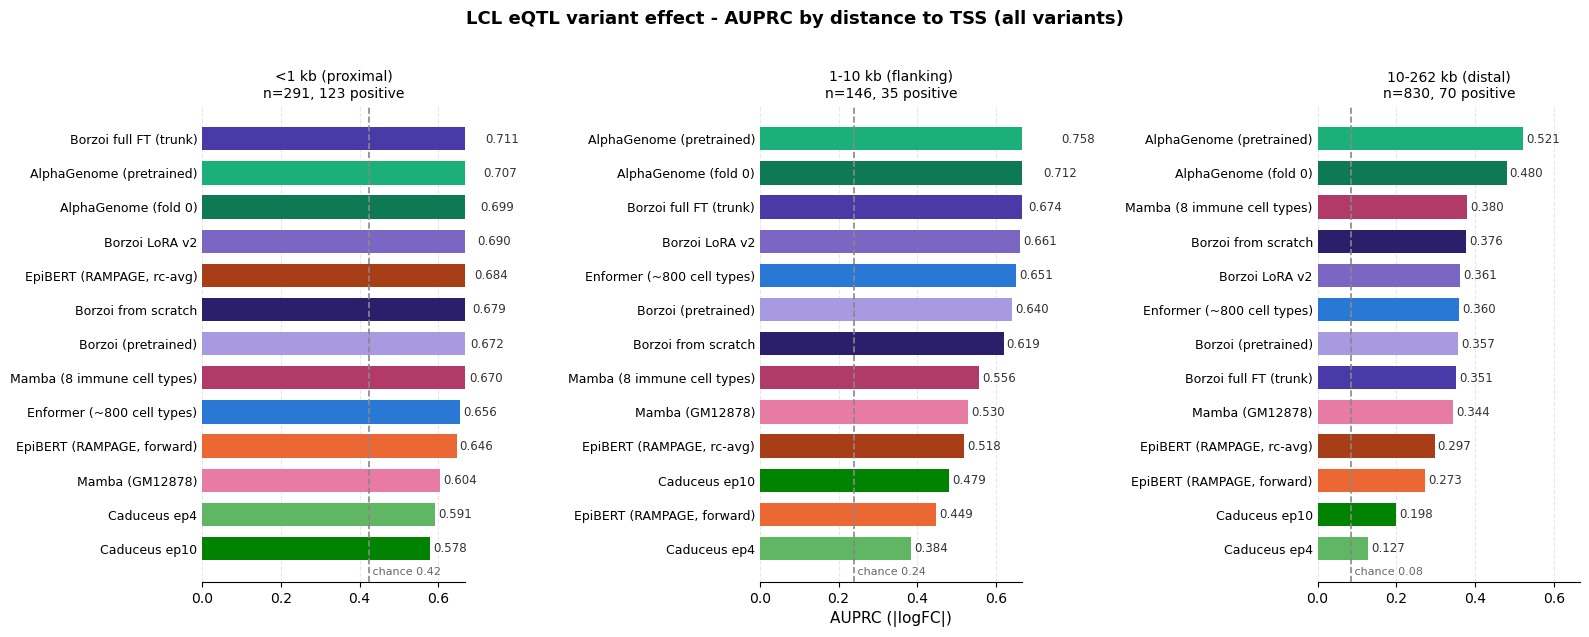

In [3]:
# §3 - AUPRC by distance bin.
def auprc_table(score_key='logfc', row_mask=None):
    """AUPRC per (distance bin, arm). row_mask further restricts every bin."""
    out = np.zeros((len(BIN_NAMES), len(ARMS)))
    for bi, dm in enumerate(DIST_MASKS):
        m = dm if row_mask is None else (dm & row_mask)
        for ai, a in enumerate(ARMS):
            pr, rc, _ = precision_recall_curve(labels[m], SCORES[a.key][score_key][m])
            out[bi, ai] = auc(rc, pr)
    return out


def plot_auprc_panels(auprc, title, row_mask=None, fname=None):
    n_used = DIST_MASKS if row_mask is None else [d & row_mask for d in DIST_MASKS]
    fig, axes = plt.subplots(1, 3, figsize=(16, 6.2), sharex=True)
    for bi, ax in enumerate(axes):
        order = np.argsort(auprc[bi])[::-1]
        y = np.arange(len(ARMS))
        ax.barh(y, auprc[bi][order], height=0.68,
                color=[ARMS[i].color for i in order], zorder=3)
        ax.set_yticks(y)
        ax.set_yticklabels([ARMS[i].label for i in order], fontsize=9)
        ax.invert_yaxis()
        for yi, i in enumerate(order):
            ax.text(auprc[bi][i] + 0.008, yi, f'{auprc[bi][i]:.3f}',
                    va='center', ha='left', fontsize=8.5, color='#333333')
        chance = labels[n_used[bi]].mean()
        ax.axvline(chance, ls='--', lw=1.2, color='#888888', zorder=4)
        # x in data coords, y in axes fraction -> pinned to the bottom, never the title
        ax.text(chance, 0.01, f' chance {chance:.2f}', fontsize=8, color='#666666',
                ha='left', va='bottom', transform=ax.get_xaxis_transform())
        ax.set_xlim(0, min(1.0, auprc[bi].max() * 1.28))
        ax.set_title(f'{BIN_NAMES[bi]}\nn={int(n_used[bi].sum())}, '
                     f'{int(labels[n_used[bi]].sum())} positive', fontsize=10)
        ax.grid(axis='x', ls='--', alpha=0.3, zorder=0)
        ax.set_axisbelow(True)
        for s in ('top', 'right', 'left'):
            ax.spines[s].set_visible(False)
        ax.tick_params(axis='y', length=0)
    axes[1].set_xlabel('AUPRC (|logFC|)', fontsize=11)
    fig.suptitle(title, fontsize=13, fontweight='bold', y=1.02)
    fig.tight_layout()
    if fname:
        fig.savefig(os.path.join(FIG_DIR, fname), dpi=160, bbox_inches='tight')
    plt.show()


AUPRC_ALL = auprc_table('logfc')
plot_auprc_panels(AUPRC_ALL,
                  'LCL eQTL variant effect - AUPRC by distance to TSS (all variants)',
                  fname='nb8_auprc_all.png')


## 4. The same table, as numbers

In [4]:
# §4 - summary table.
def auprc_frame(auprc):
    df = pd.DataFrame(auprc.T, index=[a.label for a in ARMS], columns=BIN_NAMES)
    df.insert(0, 'family', [a.family for a in ARMS])
    return df.round(4)


df_all = auprc_frame(AUPRC_ALL)
chance_row = pd.DataFrame([['--'] + [round(labels[m].mean(), 4) for m in DIST_MASKS]],
                          index=['(chance)'], columns=df_all.columns)
display(pd.concat([df_all, chance_row]))


,family,<1 kb (proximal),1-10 kb (flanking),10-262 kb (distal)
Enformer (~800 cell types),Enformer,0.6560,0.6505,0.3603
Mamba (GM12878),Mamba,0.6037,0.5296,0.3442
Mamba (8 immune cell types),Mamba,0.6699,0.5559,0.3799
Borzoi (pretrained),Borzoi,0.6725,0.6396,0.3571
Borzoi LoRA v2,Borzoi,0.6895,0.6611,0.3611
Borzoi full FT (trunk),Borzoi,0.7109,0.6737,0.3513
Borzoi from scratch,Borzoi,0.6791,0.6188,0.3761
Caduceus ep4,Caduceus,0.5909,0.3844,0.1270
Caduceus ep10,Caduceus,0.5780,0.4795,0.1984
AlphaGenome (pretrained),AlphaGenome,0.7070,0.7579,0.5207


## 5. Support is not equal across arms — and it changes the distal panel

A variant can only affect a model's prediction if it was inside the sequence the model was
shown, and the eval scripts disagree on that:

    Enformer       input   196,608 bp  ->  reaches +/-  98,304 bp  ->  1023 scorable
    AlphaGenome    input 1,048,576 bp  ->  reaches +/- 524,288 bp  ->  1331 scorable
    everything else input  524,288 bp  ->  reaches +/- 262,144 bp  ->  1267 scorable

(Do not read this off the output span — that describes where the *predictions* live, not
which variants the model could see. Gate 5 derives the real boundary from the data.)

Unscorable rows score `0.0` rather than being dropped, which pins them to the bottom of the
ranking — and because they are overwhelmingly negatives, ranking them last is *free
accuracy* for the arm that could not see them. The distal bin runs to 262 kb, so Enformer's
244 unseen variants sit inside it.

AlphaGenome's extra reach cuts the other way and costs it nothing: its 64 additional rows
are all beyond 262 kb, past the last bin, so no figure ever reads them.

Read §3 and §5 together — §3 is "how does each arm do on the benchmark as written", §5 is
"how do the arms compare when asked the same question".

,input window (bp),reach from TSS (bp),output span (bp),scorable,flat in window,last scored (bp),first unscored (bp),unscorable in distal bin
arm,,,,,,,,
Enformer (~800 cell types),196608,98304,114688,1023,0,98254,98380.0,244
Mamba (GM12878),524288,262144,114688,1267,0,261162,262536.0,0
Mamba (8 immune cell types),524288,262144,114688,1267,0,261162,262536.0,0
Borzoi (pretrained),524288,262144,196608,1267,0,261162,262536.0,0
Borzoi LoRA v2,524288,262144,196608,1267,0,261162,262536.0,0
Borzoi full FT (trunk),524288,262144,196608,1267,0,261162,262536.0,0
Borzoi from scratch,524288,262144,196608,1267,0,261162,262536.0,0
Caduceus ep4,524288,262144,196608,1267,0,261162,262536.0,0
Caduceus ep10,524288,262144,196608,1267,0,261162,262536.0,0



common support: 1023 / 1331 variants scorable by every arm
dropped from the distal bin: 244 variants (10 positive, 4.1% -- vs 8.4% in the bin overall)
the dropped rows are mostly negatives, so scoring them 0.0 inflates any arm that cannot see them


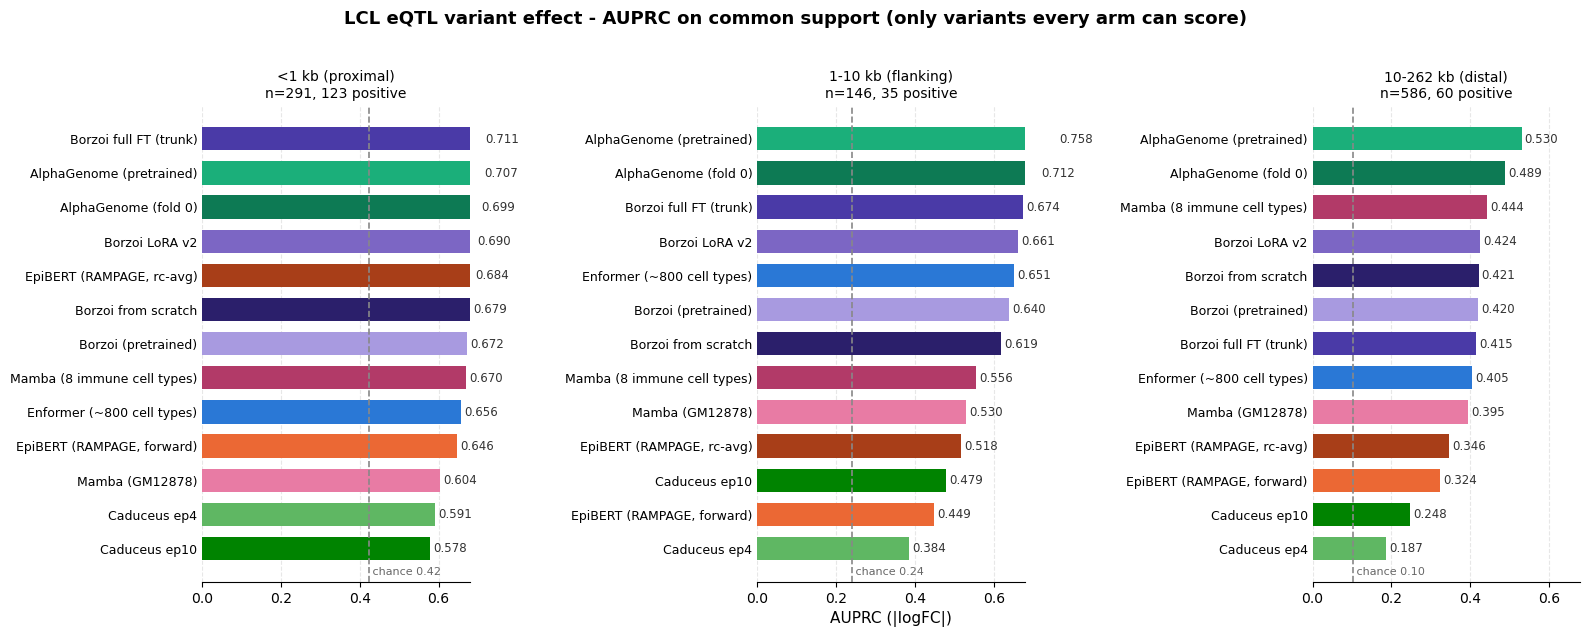


change from restricting to common support (common - all):


,<1 kb (proximal),1-10 kb (flanking),10-262 kb (distal)
Enformer (~800 cell types),0.0,0.0,0.0445
Mamba (GM12878),0.0,0.0,0.0507
Mamba (8 immune cell types),0.0,0.0,0.0636
Borzoi (pretrained),0.0,0.0,0.0626
Borzoi LoRA v2,0.0,0.0,0.0630
Borzoi full FT (trunk),0.0,0.0,0.0633
Borzoi from scratch,0.0,0.0,0.0453
Caduceus ep4,0.0,0.0,0.0599
Caduceus ep10,0.0,0.0,0.0493
AlphaGenome (pretrained),0.0,0.0,0.0096


In [5]:
# §5 - support accounting, then the common-support comparison.
rows = []
for a in ARMS:
    u = ~SCORABLE[a.key]
    rows.append({
        'arm': a.label,
        'input window (bp)': a.input_bp,
        'reach from TSS (bp)': a.input_bp // 2,
        'output span (bp)': FULL_BINS[a.key] * a.bin_bp,
        'scorable': int(SCORABLE[a.key].sum()),
        'flat in window': int(FLAT[a.key].sum()),
        'last scored (bp)': int(distances[SCORABLE[a.key]].max()),
        'first unscored (bp)': int(distances[u].min()) if u.any() else None,
        'unscorable in distal bin': int((u & DIST_MASKS[2]).sum()),
    })
display(pd.DataFrame(rows).set_index('arm'))

lost = ~COMMON & DIST_MASKS[2]
print(f'\ncommon support: {COMMON.sum()} / {N_QTL} variants scorable by every arm')
print(f'dropped from the distal bin: {int(lost.sum())} variants '
      f'({int(labels[lost].sum())} positive, {labels[lost].mean():.1%} -- '
      f'vs {labels[DIST_MASKS[2]].mean():.1%} in the bin overall)')
print('the dropped rows are mostly negatives, so scoring them 0.0 inflates any arm that '
      'cannot see them')

AUPRC_COMMON = auprc_table('logfc', row_mask=COMMON)
plot_auprc_panels(AUPRC_COMMON,
                  'LCL eQTL variant effect - AUPRC on common support '
                  '(only variants every arm can score)',
                  row_mask=COMMON, fname='nb8_auprc_common.png')

delta = pd.DataFrame((AUPRC_COMMON - AUPRC_ALL).T,
                     index=[a.label for a in ARMS], columns=BIN_NAMES).round(4)
print('\nchange from restricting to common support (common - all):')
display(delta)


## 6. Precision-recall curves

Pooled over all distances, on common support, so every curve is built from the same
variants. Thirteen overlapping curves in one panel is past what colour can carry, so the
families are split across three facets with shared axes; legends are sorted by AUC.

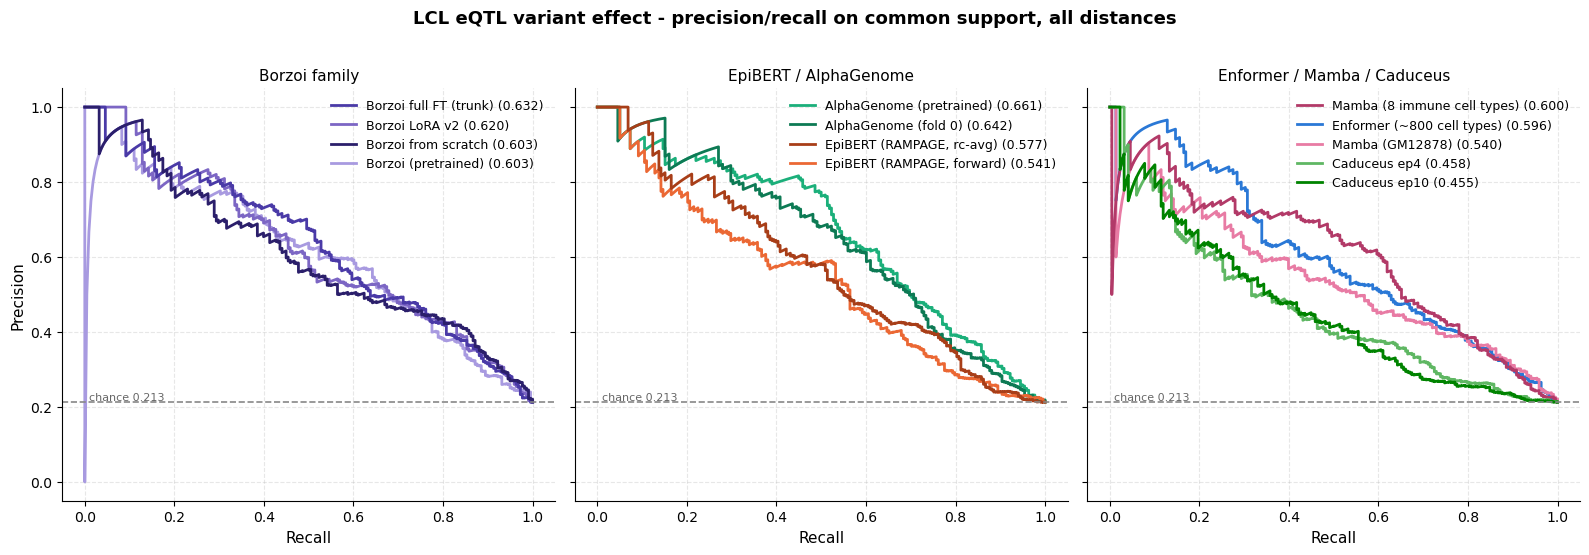

In [6]:
# §6 - PR curves on common support, all distances pooled.
FACETS = [('Borzoi family', ['Borzoi']),
          ('EpiBERT / AlphaGenome', ['EpiBERT', 'AlphaGenome']),
          ('Enformer / Mamba / Caduceus', ['Enformer', 'Mamba', 'Caduceus'])]

chance = labels[COMMON].mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 5.4), sharex=True, sharey=True)
for ax, (facet_name, fams) in zip(axes, FACETS):
    entries = []
    for a in [x for x in ARMS if x.family in fams]:
        pr, rc, _ = precision_recall_curve(labels[COMMON], SCORES[a.key]['logfc'][COMMON])
        pr_auc = auc(rc, pr)
        line, = ax.plot(rc, pr, color=a.color, lw=2, label=a.label)
        entries.append((pr_auc, line, f'{a.label} ({pr_auc:.3f})'))
    ax.axhline(chance, ls='--', lw=1.2, color='#888888')
    ax.text(0.01, chance, f'chance {chance:.3f} ', fontsize=8, color='#666666',
            ha='left', va='bottom')
    entries.sort(reverse=True, key=lambda x: x[0])
    ax.legend([e[1] for e in entries], [e[2] for e in entries], fontsize=9,
              frameon=False, loc='upper right')
    ax.set_title(facet_name, fontsize=11)
    ax.set_xlabel('Recall', fontsize=11)
    ax.grid(ls='--', alpha=0.3)
    ax.set_axisbelow(True)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel('Precision', fontsize=11)
fig.suptitle('LCL eQTL variant effect - precision/recall on common support, all distances',
             fontsize=13, fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'nb8_pr_curves.png'), dpi=160, bbox_inches='tight')
plt.show()


## 7. Where does EpiBERT land?

The panel the notebook was built for, with the field reduced to the best arm of each other
family so the comparison is legible. Both EpiBERT modes are shown: if forward-only and
rc-averaged differ materially, the difference is orientation noise, not biology.

The shape to look for is the *slope across bins*. EpiBERT is the only arm here whose input
includes measured accessibility; it is held identical for both alleles, so it cannot leak
allele information, but it does hand the model the promoter's activity directly. The
prediction is that EpiBERT is at its most competitive in the proximal bin and falls away
fastest with distance.

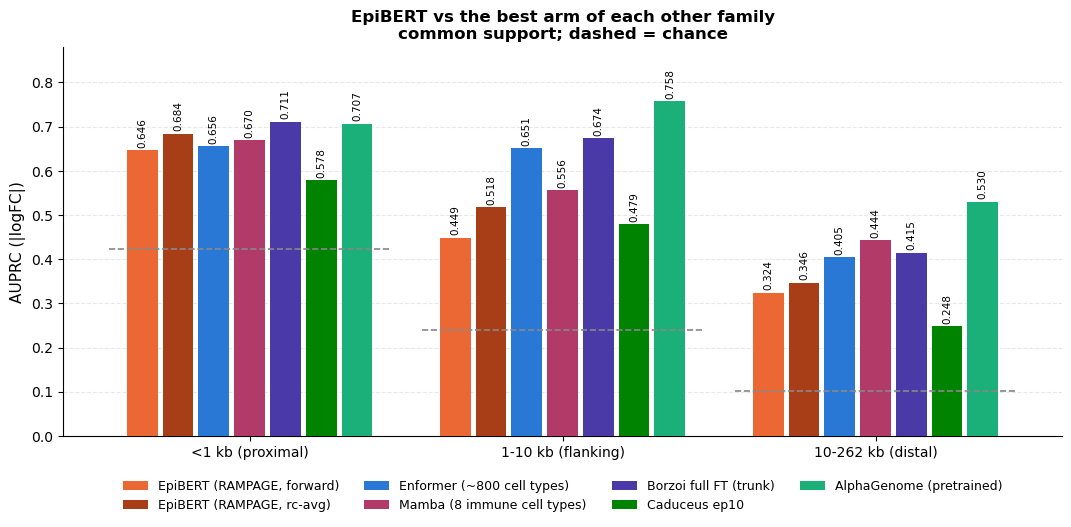

EpiBERT and the best of each other family, common support, AUPRC:


,family,<1 kb (proximal),1-10 kb (flanking),10-262 kb (distal)
"EpiBERT (RAMPAGE, forward)",EpiBERT,0.6461,0.4485,0.3240
"EpiBERT (RAMPAGE, rc-avg)",EpiBERT,0.6843,0.5178,0.3464
Enformer (~800 cell types),Enformer,0.6560,0.6505,0.4048
Mamba (8 immune cell types),Mamba,0.6699,0.5559,0.4435
Borzoi full FT (trunk),Borzoi,0.7109,0.6737,0.4146
Caduceus ep10,Caduceus,0.5780,0.4795,0.2477
AlphaGenome (pretrained),AlphaGenome,0.7070,0.7579,0.5303



proximal - distal AUPRC (how fast each arm falls off with distance):


Caduceus ep4                   0.4040
EpiBERT (RAMPAGE, rc-avg)      0.3379
Caduceus ep10                  0.3303
EpiBERT (RAMPAGE, forward)     0.3221
Borzoi full FT (trunk)         0.2963
Borzoi LoRA v2                 0.2655
Borzoi from scratch            0.2577
Borzoi (pretrained)            0.2528
Enformer (~800 cell types)     0.2512
Mamba (8 immune cell types)    0.2264
AlphaGenome (fold 0)           0.2108
Mamba (GM12878)                0.2088
AlphaGenome (pretrained)       0.1766
dtype: float64

In [7]:
# §7 - EpiBERT against the best of each other family, common support.
best = {}
for a in ARMS:
    if a.family == 'EpiBERT':
        continue
    i = KEYS.index(a.key)
    score = AUPRC_COMMON[:, i].mean()
    if a.family not in best or score > best[a.family][1]:
        best[a.family] = (a, score)
panel = [a for a in ARMS if a.family == 'EpiBERT'] + [v[0] for v in best.values()]
idx = [KEYS.index(a.key) for a in panel]

fig, ax = plt.subplots(figsize=(11, 5.4))
x = np.arange(len(BIN_NAMES))
w = 0.8 / len(panel)
for j, i in enumerate(idx):
    off = (j - (len(panel) - 1) / 2) * w
    ax.bar(x + off, AUPRC_COMMON[:, i], width=w * 0.86,
           color=ARMS[i].color, label=ARMS[i].label, zorder=3)
    for bi in range(len(BIN_NAMES)):
        ax.text(x[bi] + off, AUPRC_COMMON[bi, i] + 0.006, f'{AUPRC_COMMON[bi, i]:.3f}',
                ha='center', va='bottom', fontsize=7.5, rotation=90)
for bi, m in enumerate([d & COMMON for d in DIST_MASKS]):
    ax.hlines(labels[m].mean(), x[bi] - 0.45, x[bi] + 0.45,
              ls='--', lw=1.2, color='#888888', zorder=4)
ax.set_xticks(x)
ax.set_xticklabels(BIN_NAMES, fontsize=10)
ax.set_ylabel('AUPRC (|logFC|)', fontsize=11)
ax.set_ylim(0, AUPRC_COMMON[:, idx].max() * 1.16)
ax.set_title('EpiBERT vs the best arm of each other family\n'
             'common support; dashed = chance', fontsize=12, fontweight='bold')
# legend below the axes: at 21 bars the value labels own the plot area
ax.legend(fontsize=9, frameon=False, ncol=4, loc='upper center',
          bbox_to_anchor=(0.5, -0.1), borderaxespad=0)
ax.grid(axis='y', ls='--', alpha=0.3, zorder=0)
ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'nb8_epibert_panel.png'), dpi=160, bbox_inches='tight')
plt.show()

print('EpiBERT and the best of each other family, common support, AUPRC:')
display(auprc_frame(AUPRC_COMMON).iloc[idx])

epi = [KEYS.index(a.key) for a in ARMS if a.family == 'EpiBERT']
drop = AUPRC_COMMON[0, :] - AUPRC_COMMON[2, :]
print('\nproximal - distal AUPRC (how fast each arm falls off with distance):')
display(pd.Series(drop, index=[a.label for a in ARMS]).sort_values(ascending=False).round(4))


---

# Part 2 — alternative TSS

§1–§7 read one canonical TSS per gene out of `ensemblTSS.txt`, so a variant sitting on a
gene's *other* promoter is scored in a 2048 bp window centred on the wrong one. Part 2
redoes §2–§7 with a mask that also covers every annotated alternative TSS, and reports the
difference. Part 1 is left untouched so the two can be subtracted.

Nothing is re-run on a GPU. Every arm's array holds its **full** output span — that is what
§1 slices 2048 bp out of — so an alternative-TSS mask is a wider, multi-peaked selection
over predictions that are already on disk. What the arrays do limit is *reach*, and this is
the **output** span, not the input span §5 is about:

| arms | output | reach from the canonical TSS |
|---|---|---|
| Enformer, Mamba | 896 × 128 bp | ±57,344 bp |
| Borzoi, Caduceus | 6144 × 32 bp | ±98,304 bp |
| EpiBERT | 4092 × 128 bp | ±261,888 bp |
| AlphaGenome | 1,048,576 × 1 bp | ±524,288 bp |

An alternative TSS outside an arm's output span is dropped from that arm's mask, which is
what `EP_linking9.make_score_vector` does, and a row the arm cannot score at all keeps `0.0`
and ranks last, which is what §2 and §5 already do. Neither is compensated for: a narrow
output span buys an arm a *narrower question*, and §13 is where that shows up.

## 8. The annotation

Alternative TSS are every annotated transcript start of the gene, taken straight from
**gencode v49**. `build_rna_info.py` builds the same thing for the E-P linking work but
keeps only `protein_coding` genes and only those expressed in K562, which between them
would drop 150 of the 658 genes here — so the GTF is re-parsed rather than reused. The
parse is a byte-level scan of the 3.3 GB file for `\ttranscript\t`, about 5 s.

In [8]:
# §8 - alternative TSS for every eQTL gene, straight from the GTF.
import re
import time

GTF_PATH = '/data1/lesliec/sarthak/data/DE_danwei/gencode.v49.annotation.gtf'

MAIN_HALF_BP  = CENTER_BP // 2        # 1024 bp -- the main-TSS window, never changed below
ALT_HALF_BP   = 1024                  # half-width of the window placed on each alternative TSS
SWEEP_HALF_BP = [256, 512, 1024, 2048]

qtl_genes = sorted({ordered_genes[i] for i in qtls['gene_idx']})
print(f'{len(qtl_genes)} distinct genes behind the {N_QTL} eQTLs')

# GTF coordinates are 1-based and ensemblTSS.txt is in the same convention (gate 8.2), so
# the TSS is the transcript start on +, the transcript end on -, with no offset conversion.
_gid = re.compile(rb'gene_id "([^".]+)')
_want = set(qtl_genes)
tx_tss, gtf_chrom, gtf_strand = {}, {}, {}
_t0 = time.time()
with open(GTF_PATH, 'rb') as fh:
    for line in fh:
        if b'\ttranscript\t' not in line:
            continue
        g = _gid.search(line).group(1).decode()
        if g not in _want:
            continue
        f = line.split(b'\t')
        st = f[6].decode()
        tx_tss.setdefault(g, set()).add(int(f[3]) if st == '+' else int(f[4]))
        gtf_chrom[g], gtf_strand[g] = f[0].decode(), st

no_gtf = [g for g in qtl_genes if g not in tx_tss]
print(f'parsed gencode v49 in {time.time() - _t0:.1f}s: {len(tx_tss)} / {len(qtl_genes)} genes '
      f'found, {len(no_gtf)} absent -> those keep the canonical TSS only')
if no_gtf:
    _no = set(no_gtf)
    _rows_no_gtf = np.array([ordered_genes[gi] in _no for gi in qtls['gene_idx']])
    print(f'        {no_gtf}  ({int(_rows_no_gtf.sum())} eQTL rows)')

# ============================== GATE, part 2 ==============================
# 8.1 the GTF must agree with genes.pickle about where the gene is and which way it points
bad = [g for g in tx_tss
       if 'chr' + str(gene_annotation[g][0]) != gtf_chrom[g]
       or (gene_annotation[g][3] == 1) != (gtf_strand[g] == '+')]
assert not bad, f'GATE FAILED: GTF and genes.pickle disagree about {bad[:5]}'
print(f'\ngate 8.1: chromosome and strand match genes.pickle for all {len(tx_tss)} genes')

# 8.2 the canonical TSS must itself be an annotated transcript start, or the offsets below
#     are differences between two coordinate systems rather than two promoters
_near = np.array([min(abs(t - geneTSS_dic[g]) for t in tx_tss[g]) for g in tx_tss])
_exact = int((_near == 0).sum())
assert _exact / _near.size > 0.9, (
    f'GATE FAILED: only {_exact}/{_near.size} canonical TSS land exactly on an annotated '
    f'transcript start -- ensemblTSS.txt and the GTF are not in the same coordinate system')
print(f'gate 8.2: {_exact} / {_near.size} canonical TSS sit exactly on an annotated transcript '
      f'start ({(_near <= 10).mean():.1%} within 10 bp) -- same coordinate system')
_far = sorted(((int(d), g) for d, g in zip(_near, tx_tss) if d > 1000), reverse=True)
if _far:
    print('        canonical TSS >1 kb from every annotated transcript start:')
    for d, g in _far:
        print(f'          {g}  {d:,} bp  ({gene_annotation[g][4]})')

# --- per-row offsets of every alternative TSS from the window centre ----------------
# Only promoters at least MAIN_HALF_BP away are kept: anything nearer is already inside the
# main window, so adding it would change nothing at the default width and would silently
# widen the *main* window during the §16 sweep.
ALT_OFFSETS = []
for i in range(N_QTL):
    g = ordered_genes[qtls['gene_idx'].iloc[i]]
    t0 = geneTSS_dic[g]
    ALT_OFFSETS.append(np.array(sorted(t - t0 for t in tx_tss.get(g, ())
                                       if abs(t - t0) >= MAIN_HALF_BP), dtype=int))

n_alt = np.array([len(o) for o in ALT_OFFSETS])
print(f'\n{int((n_alt > 0).sum())} / {N_QTL} rows have at least one alternative TSS '
      f'>= {MAIN_HALF_BP} bp from the canonical one '
      f'(median {int(np.median(n_alt[n_alt > 0]))} per such row, max {n_alt.max()})')

# An alternative TSS is visible to an arm iff its own bin exists, i.e. iff
# floor(o / bin_bp) + n_bins // 2 is in [0, n_bins) -- which for these even bin counts is
# exactly -reach <= o < reach. IN_SPAN is that predicate, and the mask in §9 uses the same
# test, so these counts cannot drift away from what is actually being integrated.
def in_span(offsets, key):
    reach = (FULL_BINS[key] // 2) * ARM[key].bin_bp
    o = np.asarray(offsets, dtype=int)
    return (o >= -reach) & (o < reach)


print(f'\n{"arm":<30}{"output reach":>16}{"rows w/ alt TSS in reach":>26}{"alt TSS in reach":>19}')
for a in ARMS:
    reach = (FULL_BINS[a.key] // 2) * a.bin_bp
    inr = np.array([int(in_span(o, a.key).sum()) for o in ALT_OFFSETS])
    print(f'{a.label:<30}{"+/-" + format(reach, ","):>16}{int((inr > 0).sum()):>26}'
          f'{int(inr.sum()):>19}')
print(f'{"(annotated, any reach)":<30}{"":>16}{int((n_alt > 0).sum()):>26}{int(n_alt.sum()):>19}')

658 distinct genes behind the 1331 eQTLs


parsed gencode v49 in 3.5s: 653 / 658 genes found, 5 absent -> those keep the canonical TSS only
        ['ENSG00000230836', 'ENSG00000237899', 'ENSG00000241770', 'ENSG00000272541', 'ENSG00000289620']  (5 eQTL rows)

gate 8.1: chromosome and strand match genes.pickle for all 653 genes
gate 8.2: 621 / 653 canonical TSS sit exactly on an annotated transcript start (97.1% within 10 bp) -- same coordinate system
        canonical TSS >1 kb from every annotated transcript start:
          ENSG00000287250  4,210 bp  ()

1037 / 1331 rows have at least one alternative TSS >= 1024 bp from the canonical one (median 4 per such row, max 87)

arm                               output reach  rows w/ alt TSS in reach   alt TSS in reach
Enformer (~800 cell types)           +/-57,344                      1006               5362
Mamba (GM12878)                      +/-57,344                      1006               5362
Mamba (8 immune cell types)          +/-57,344                      1006              

## 9. The mask, and a scorer that reproduces §2 when there is nothing to add

`tss_bin_intervals` returns the bins covered by the main-TSS window **plus** one window on
each alternative TSS, merged so overlapping promoters are not double-counted. Bin `j` spans

    [(j - centre) * bin_bp, (j - centre + 1) * bin_bp)

in bp relative to the canonical TSS, with `centre = n_bins // 2` — the same arithmetic §1
uses to cut its window, so with no alternative TSS and `main_half = 1024` it reproduces §1's
slice bin-for-bin on all six geometries. Gate 9.1 asserts exactly that, which is what makes
the 1 bp, 32 bp and 128 bp arms comparable: the mask is specified in **bp**, so every arm
integrates the same physical region and only the discretisation differs.

Two rules carried over from `EP_linking9.make_score_vector`: an alternative TSS whose own
bin is outside the output span is skipped entirely, and a window that merely runs off the
edge is clipped.

**One metric survives this intact.** `logfc` is a ratio of means and `jsd` is a distance
between normalised profiles, so both are insensitive to how many bins the mask holds.
`lpd` is a *sum* of per-bin log ratios and `ies2` is built from it, so a gene with 40
alternative promoters gets a mechanically larger score than one with none. They are
computed for continuity with §2 but every figure below uses `logfc`, as in Part 1.

In [9]:
# §9 - the alt-TSS mask and the streaming scorer.
def tss_bin_intervals(n_bins, bin_bp, alt_offsets, main_half=None, alt_half=None):
    """Merged [lo, hi) bin intervals for the main TSS plus each alternative TSS.

    Intervals rather than a boolean mask: AlphaGenome has 1,048,576 one-bp bins, and
    allocating a mask of that size once per row per window width is most of the runtime.
    """
    main_half = MAIN_HALF_BP if main_half is None else main_half
    alt_half = ALT_HALF_BP if alt_half is None else alt_half
    centre = n_bins // 2
    iv = []
    for o, half in [(0, main_half)] + [(int(o), alt_half) for o in alt_offsets]:
        if half <= 0:
            continue
        # EP_linking9's rule: skip the promoter outright if its own bin is off the array.
        # This is the predicate §8's in_span() reports on.
        cbin = int(np.floor(o / bin_bp)) + centre
        if cbin < 0 or cbin >= n_bins:
            continue
        lo = max(0, int(np.floor((o - half) / bin_bp)) + centre)
        hi = min(n_bins, int(np.floor((o + half - 1) / bin_bp)) + centre + 1)
        if hi > lo:
            iv.append([lo, hi])
    iv.sort()
    merged = []
    for lo, hi in iv:
        if merged and lo <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], hi)
        else:
            merged.append([lo, hi])
    return merged


# --- gate 9.1: with no alternative TSS this is §1's window, on every geometry ---------
for a in ARMS:
    iv = tss_bin_intervals(FULL_BINS[a.key], a.bin_bp, [], MAIN_HALF_BP, 0)
    n_bins_expected = CENTER_BP // a.bin_bp
    cs = FULL_BINS[a.key] // 2 - n_bins_expected // 2
    assert iv == [[cs, cs + n_bins_expected]], (
        f'GATE FAILED: {a.key} alt mask with no alternative TSS is {iv}, '
        f'§1 used bins [{cs}, {cs + n_bins_expected})')
print(f'gate 9.1: with no alternative TSS the mask reproduces §1 window on all {len(ARMS)} arms')


def score_arm_alt(a, alt_halves):
    """One streaming pass over an arm's full output array.

    Returns {alt_half: {metric: (N_QTL,) array}}, all metrics already under np.abs() as in
    §2. Rows the arm could not score keep 0.0 in every metric and so still rank last.
    """
    src = (zarr.open(QTL_DIR + a.fname, mode='r') if a.fname.endswith('.zarr')
           else np.load(QTL_DIR + a.fname, mmap_mode='r'))
    n_bins = FULL_BINS[a.key]
    out = {h: {nm: np.zeros(N_QTL) for nm in SCORE_NAMES} for h in alt_halves}
    n_dropped = 0
    for i in range(N_QTL):
        if not SCORABLE[a.key][i]:
            continue
        row = np.asarray(src[i], dtype=np.float64)      # (n_bins, 2) = (bins, ref/alt)
        for h in alt_halves:
            iv = tss_bin_intervals(n_bins, a.bin_bp, ALT_OFFSETS[i], MAIN_HALF_BP, h)
            sel = np.concatenate([row[lo:hi] for lo, hi in iv], axis=0)
            r, alt = sel[:, 0], sel[:, 1]
            assert (r > 0).all() and (alt > 0).all(), (
                f'GATE FAILED: {a.key} row {i} has a non-positive prediction inside the '
                f'alt-TSS mask -- np.log would produce -inf. §1 gate 2 only covered the '
                f'central 2048 bp.')
            lpd = np.abs(np.log(alt) - np.log(r)).sum()
            jsd = jensenshannon(alt, r)
            lf = np.log2(r.mean() / alt.mean())
            for nm, v in zip(SCORE_NAMES, [lf, lpd, jsd, lf * jsd, lpd * jsd]):
                out[h][nm][i] = abs(v)
        n_dropped += int((~in_span(ALT_OFFSETS[i], a.key)).sum())
    return out, n_dropped

gate 9.1: with no alternative TSS the mask reproduces §1 window on all 13 arms


### Scoring all thirteen arms

`alt_half = 0` is scored alongside the real widths as a free parity check: it collapses the
mask back to §1's window, so it must reproduce §2's `SCORES` to floating point. If it does
not, the mask arithmetic is wrong and nothing below means anything.

AlphaGenome dominates the runtime — its zarr chunks are one whole 1,048,576 × 2 row each, so
this streams about 11 GB per arm off disk. Expect a few minutes for the cell as a whole.

In [10]:
# §10 - score every arm, at every window width, in one pass each.
HALVES = sorted(set(SWEEP_HALF_BP + [ALT_HALF_BP, 0]))
SCORES_ALT, SWEEP_LOGFC, DROPPED = {}, {}, {}

_t0 = time.time()
print(f'{"arm":<30}{"parity vs §2":>16}{"alt TSS dropped":>18}{"med |logFC| shift":>20}{"s":>7}')
for a in ARMS:
    _t = time.time()
    res, n_dropped = score_arm_alt(a, HALVES)
    SCORES_ALT[a.key] = res[ALT_HALF_BP]
    SWEEP_LOGFC[a.key] = {h: res[h]['logfc'] for h in SWEEP_HALF_BP}
    DROPPED[a.key] = n_dropped

    #relative, because lpd is a sum over thousands of bins and can be O(1e3)
    parity = max(float(np.max(np.abs(res[0][nm] - SCORES[a.key][nm])
                              / np.maximum(np.abs(SCORES[a.key][nm]), 1e-12)))
                 for nm in SCORE_NAMES)
    assert parity < 1e-9, (
        f'GATE FAILED: {a.key} at alt_half=0 differs from §2 by {parity:.3e} (relative); the alt-TSS '
        f'mask does not reduce to the §1 window')
    s = SCORABLE[a.key]
    shift = np.median(SCORES_ALT[a.key]['logfc'][s]) - np.median(SCORES[a.key]['logfc'][s])
    print(f'{a.label:<30}{parity:>16.1e}{n_dropped:>18}{shift:>20.2e}{time.time() - _t:>7.0f}')

print(f'\ngate 10.1: every arm reproduces §2 exactly when the alternative TSS are removed')
print(f'total {time.time() - _t0:.0f}s')

arm                               parity vs §2   alt TSS dropped   med |logFC| shift      s


Enformer (~800 cell types)             0.0e+00              1101            3.41e-04      0


Mamba (GM12878)                        0.0e+00              1780            6.05e-05      0


Mamba (8 immune cell types)            0.0e+00              1780            4.57e-05      0


Borzoi (pretrained)                    0.0e+00              1015            1.36e-04      0


...

Caduceus ep10                          0.0e+00              1015           -2.72e-05      0


AlphaGenome (pretrained)               0.0e+00                 2           -1.19e-04     12


AlphaGenome (fold 0)                   0.0e+00                 2           -3.13e-04     12


EpiBERT (RAMPAGE, forward)             0.0e+00               113           -3.59e-04      0


EpiBERT (RAMPAGE, rc-avg)              0.0e+00               113           -3.24e-04      0

gate 10.1: every arm reproduces §2 exactly when the alternative TSS are removed
total 28s


## 11. AUPRC by distance to TSS, with alternative TSS in the mask

The §3 figure, rebuilt on `SCORES_ALT`. Distance bins are unchanged — still
`|variant − canonical TSS|` — so this panel and §3's are subtractable row for row. §17 asks
the separate question of what happens when *distance itself* is redefined.

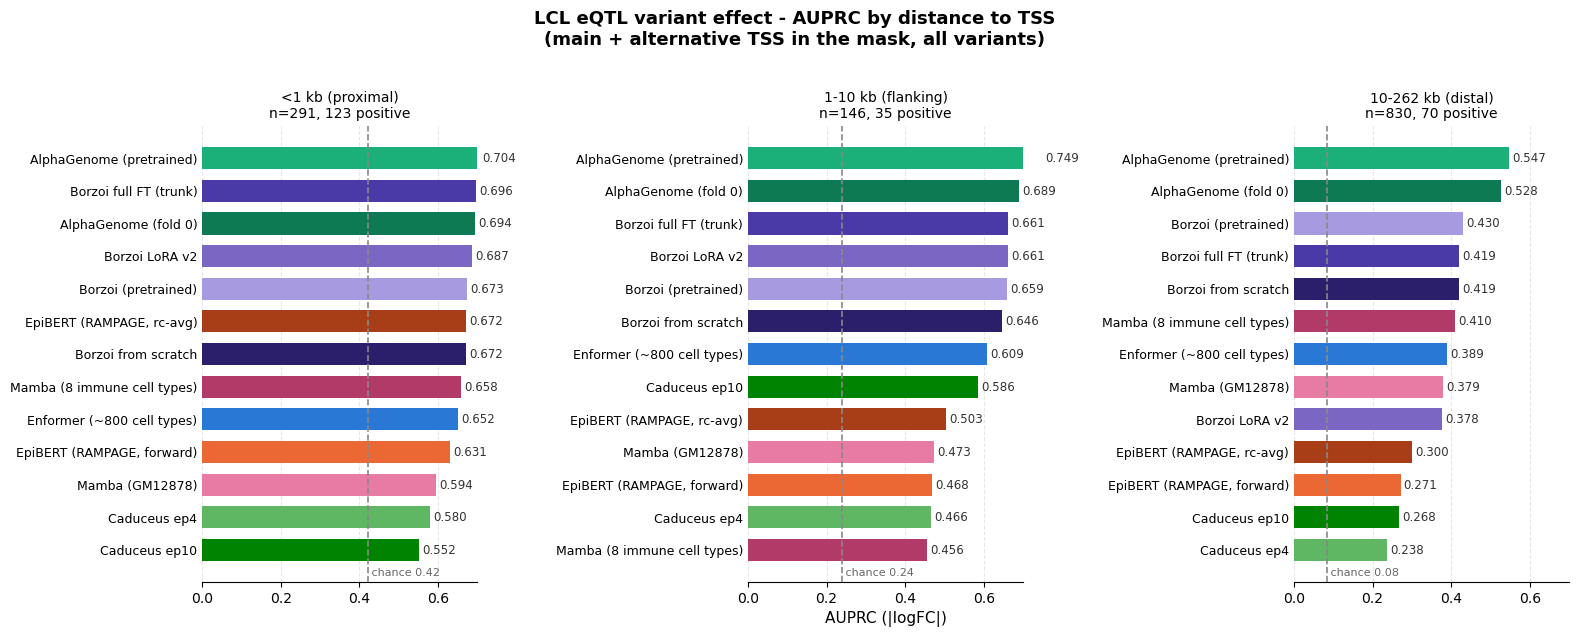

In [11]:
# §11 - AUPRC by distance bin, alt-TSS mask.
def auprc_table_from(score_dict, score_key='logfc', row_mask=None):
    """§3's auprc_table, but over an explicit score dict instead of the §2 global."""
    out = np.zeros((len(BIN_NAMES), len(ARMS)))
    for bi, dm in enumerate(DIST_MASKS):
        m = dm if row_mask is None else (dm & row_mask)
        for ai, a in enumerate(ARMS):
            pr, rc, _ = precision_recall_curve(labels[m], score_dict[a.key][score_key][m])
            out[bi, ai] = auc(rc, pr)
    return out


#per-arm: how many scorable rows the alt-TSS mask actually moved, i.e. rows with at least
#one alternative promoter inside that arm's output span. An arm with 0 here cannot differ
#from §3 whatever the figure shows.
ROWS_MOVED = {}
for a in ARMS:
    ROWS_MOVED[a.key] = np.array([SCORABLE[a.key][i] and bool(in_span(ALT_OFFSETS[i], a.key).any())
                                  for i in range(N_QTL)])

AUPRC_ALT = auprc_table_from(SCORES_ALT)
plot_auprc_panels(AUPRC_ALT,
                  'LCL eQTL variant effect - AUPRC by distance to TSS\n'
                  '(main + alternative TSS in the mask, all variants)')

## 12. The same table, as numbers — and what the alternative TSS did

`delta = alt − canonical`, positive meaning the alternative-TSS mask helped. Read it next to
`rows moved`: an arm whose mask barely changed cannot move much either way, so a small delta
on a small `rows moved` says nothing, while a small delta on a large one is a real null.

In [12]:
# §12 - alt-TSS AUPRC table and the delta against §3.
df_alt = auprc_frame(AUPRC_ALT)
chance_row = pd.DataFrame([['--'] + [round(labels[m].mean(), 4) for m in DIST_MASKS]],
                          index=['(chance)'], columns=df_alt.columns)
print('AUPRC with the alternative-TSS mask (all variants):')
display(pd.concat([df_alt, chance_row]))

delta_alt = pd.DataFrame((AUPRC_ALT - AUPRC_ALL).T,
                         index=[a.label for a in ARMS], columns=BIN_NAMES).round(4)
delta_alt.insert(0, 'rows moved', [int(ROWS_MOVED[a.key].sum()) for a in ARMS])
print('\nchange from adding the alternative TSS (alt - canonical):')
display(delta_alt)

print('\nmean delta across the arms, by distance bin:')
display(pd.Series((AUPRC_ALT - AUPRC_ALL).mean(axis=1), index=BIN_NAMES).round(4))

#the same thing restricted to the rows the mask actually moved, per arm -- on those rows the
#two scores differ by construction, so this is where any real effect has to be visible
print('\nAUPRC on each arm\'s own moved rows only (pooled over distance), '
      'canonical vs alt-TSS mask:')
rows = []
for a in ARMS:
    m = ROWS_MOVED[a.key]
    if m.sum() < 20 or labels[m].sum() == 0:
        continue
    pr, rc, _ = precision_recall_curve(labels[m], SCORES[a.key]['logfc'][m])
    can = auc(rc, pr)
    pr, rc, _ = precision_recall_curve(labels[m], SCORES_ALT[a.key]['logfc'][m])
    alt = auc(rc, pr)
    rows.append({'arm': a.label, 'n': int(m.sum()), 'chance': round(labels[m].mean(), 4),
                 'canonical': round(can, 4), 'alt TSS': round(alt, 4),
                 'delta': round(alt - can, 4)})
display(pd.DataFrame(rows).set_index('arm'))

AUPRC with the alternative-TSS mask (all variants):


,family,<1 kb (proximal),1-10 kb (flanking),10-262 kb (distal)
Enformer (~800 cell types),Enformer,0.6519,0.6090,0.3888
Mamba (GM12878),Mamba,0.5941,0.4732,0.3791
Mamba (8 immune cell types),Mamba,0.6578,0.4555,0.4096
Borzoi (pretrained),Borzoi,0.6731,0.6589,0.4302
Borzoi LoRA v2,Borzoi,0.6866,0.6609,0.3777
Borzoi full FT (trunk),Borzoi,0.6961,0.6614,0.4194
Borzoi from scratch,Borzoi,0.6720,0.6457,0.4191
Caduceus ep4,Caduceus,0.5800,0.4665,0.2377
Caduceus ep10,Caduceus,0.5521,0.5856,0.2678
AlphaGenome (pretrained),AlphaGenome,0.7040,0.7494,0.5473



change from adding the alternative TSS (alt - canonical):


,rows moved,<1 kb (proximal),1-10 kb (flanking),10-262 kb (distal)
Enformer (~800 cell types),771,-0.0041,-0.0415,0.0285
Mamba (GM12878),947,-0.0096,-0.0564,0.0348
Mamba (8 immune cell types),947,-0.0121,-0.1004,0.0297
Borzoi (pretrained),963,0.0006,0.0192,0.0732
Borzoi LoRA v2,963,-0.0029,-0.0002,0.0166
Borzoi full FT (trunk),963,-0.0148,-0.0123,0.0681
Borzoi from scratch,963,-0.0071,0.0269,0.0430
Caduceus ep4,963,-0.0109,0.0821,0.1107
Caduceus ep10,963,-0.0259,0.1062,0.0694
AlphaGenome (pretrained),1037,-0.0030,-0.0084,0.0265



mean delta across the arms, by distance bin:


<1 kb (proximal)     -0.0094
1-10 kb (flanking)   -0.0002
10-262 kb (distal)    0.0423
dtype: float64


AUPRC on each arm's own moved rows only (pooled over distance), canonical vs alt-TSS mask:


,n,chance,canonical,alt TSS,delta
arm,,,,,
Enformer (~800 cell types),771,0.2283,0.6323,0.6348,0.0025
Mamba (GM12878),947,0.1922,0.5475,0.5366,-0.0108
Mamba (8 immune cell types),947,0.1922,0.5813,0.5755,-0.0059
Borzoi (pretrained),963,0.1921,0.5986,0.6252,0.0266
Borzoi LoRA v2,963,0.1921,0.6178,0.6214,0.0036
Borzoi full FT (trunk),963,0.1921,0.6376,0.6476,0.0100
Borzoi from scratch,963,0.1921,0.6115,0.6316,0.0201
Caduceus ep4,963,0.1921,0.4368,0.4757,0.0389
Caduceus ep10,963,0.1921,0.4557,0.4884,0.0327


## 13. Common support, and what the narrow-output arms are being asked

§5's `COMMON` is about the **input** window — which variants an arm could see at all. It is
reused unchanged, because adding alternative TSS to the mask does not change which variants
exist.

What is new is that the arms no longer integrate the same region even on common support:
Enformer and Mamba reach ±57 kb of output, so an alternative promoter 80 kb away is invisible
to them and visible to Borzoi. Nothing compensates for this — on those rows the narrow arms
are simply still answering the single-promoter question. The audit below counts how often
that happens, so an "improvement" that is really just a smaller mask is identifiable.

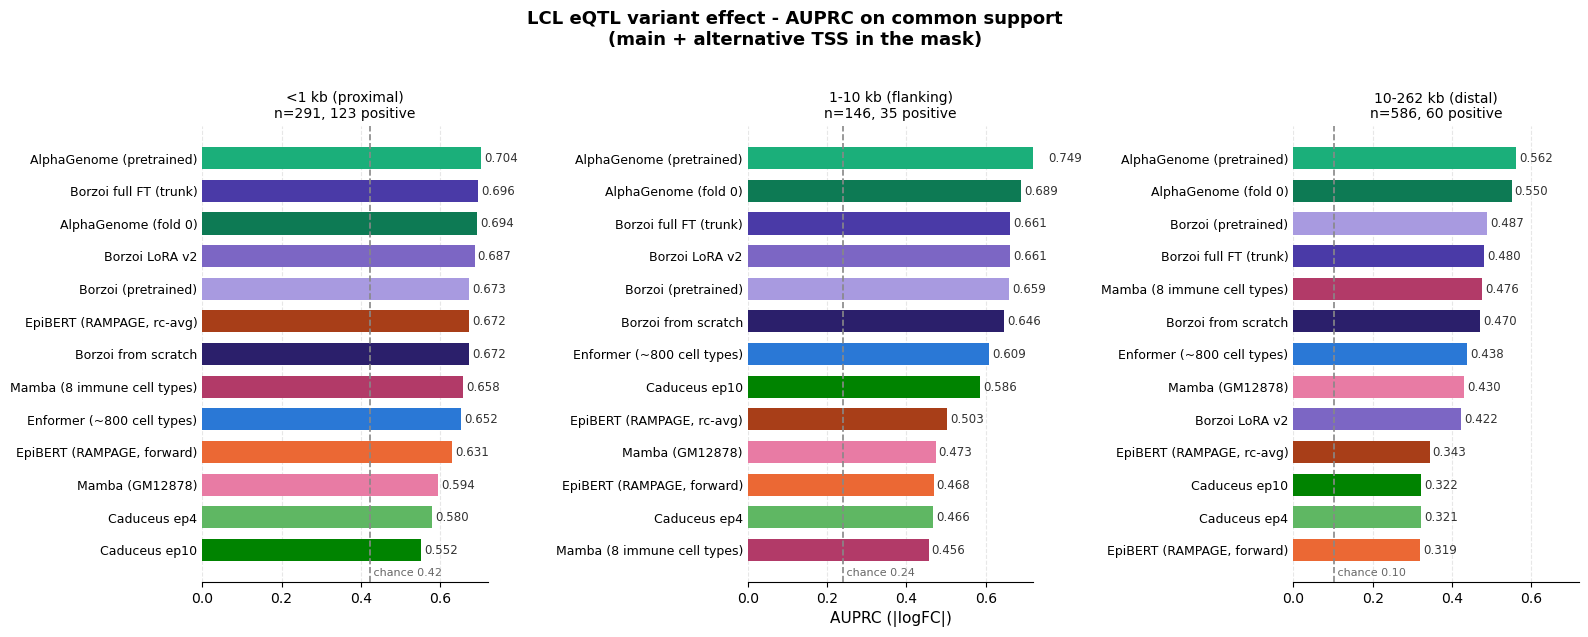

on common support, how much of the alternative-TSS mask each arm can actually see:


,output reach (bp),rows w/ any alt TSS,rows fully visible,rows partly cut,alt TSS visible,alt TSS cut
arm,,,,,,
Enformer (~800 cell types),57344,790,624,166,4064,1101
Mamba (GM12878),57344,790,624,166,4064,1101
Mamba (8 immune cell types),57344,790,624,166,4064,1101
Borzoi (pretrained),98304,790,704,86,4597,568
Borzoi LoRA v2,98304,790,704,86,4597,568
Borzoi full FT (trunk),98304,790,704,86,4597,568
Borzoi from scratch,98304,790,704,86,4597,568
Caduceus ep4,98304,790,704,86,4597,568
Caduceus ep10,98304,790,704,86,4597,568



change from adding the alternative TSS, on common support (alt - canonical):


,<1 kb (proximal),1-10 kb (flanking),10-262 kb (distal)
Enformer (~800 cell types),-0.0041,-0.0415,0.0332
Mamba (GM12878),-0.0096,-0.0564,0.0352
Mamba (8 immune cell types),-0.0121,-0.1004,0.0326
Borzoi (pretrained),0.0006,0.0192,0.0678
Borzoi LoRA v2,-0.0029,-0.0002,-0.0021
Borzoi full FT (trunk),-0.0148,-0.0123,0.0658
Borzoi from scratch,-0.0071,0.0269,0.0490
Caduceus ep4,-0.0109,0.0821,0.1339
Caduceus ep10,-0.0259,0.1062,0.0738
AlphaGenome (pretrained),-0.0030,-0.0084,0.0317


In [13]:
# §13 - common support, plus an audit of how much of the alt-TSS mask each arm can see.
AUPRC_ALT_COMMON = auprc_table_from(SCORES_ALT, 'logfc', row_mask=COMMON)
plot_auprc_panels(AUPRC_ALT_COMMON,
                  'LCL eQTL variant effect - AUPRC on common support\n'
                  '(main + alternative TSS in the mask)',
                  row_mask=COMMON)

rows = []
for a in ARMS:
    reach = (FULL_BINS[a.key] // 2) * a.bin_bp
    seen = np.array([int(in_span(o, a.key).sum()) for o in ALT_OFFSETS])
    m = COMMON & SCORABLE[a.key] & (n_alt > 0)
    rows.append({
        'arm': a.label,
        'output reach (bp)': reach,
        'rows w/ any alt TSS': int(m.sum()),
        'rows fully visible': int((m & (seen == n_alt)).sum()),
        'rows partly cut': int((m & (seen < n_alt)).sum()),
        'alt TSS visible': int(seen[m].sum()),
        'alt TSS cut': int((n_alt - seen)[m].sum()),
    })
print('on common support, how much of the alternative-TSS mask each arm can actually see:')
display(pd.DataFrame(rows).set_index('arm'))

delta_common = pd.DataFrame((AUPRC_ALT_COMMON - AUPRC_COMMON).T,
                            index=[a.label for a in ARMS], columns=BIN_NAMES).round(4)
print('\nchange from adding the alternative TSS, on common support (alt - canonical):')
display(delta_common)

## 14. Precision-recall curves

§6's facets, on common support and pooled over distance, with the alternative-TSS mask.
Dashed lines are the canonical-TSS curve for the same arm, so each facet carries both
versions without doubling the number of colours.

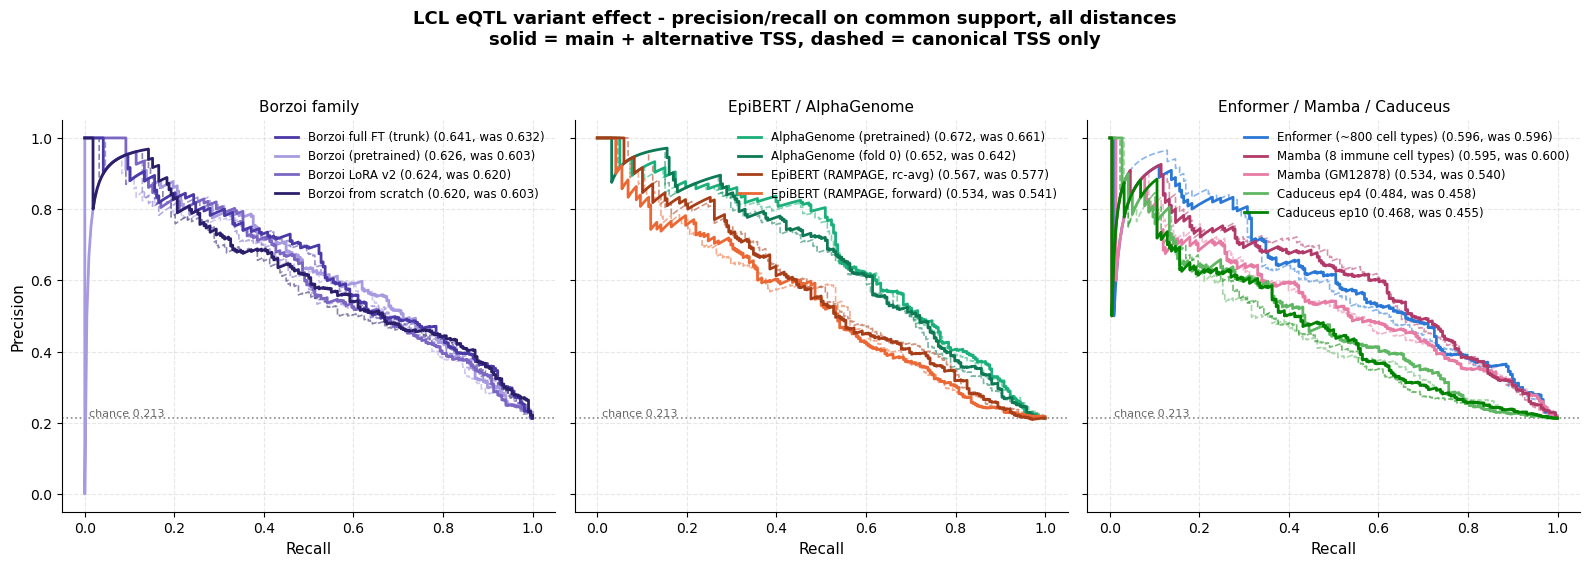

In [14]:
# §14 - PR curves on common support, alt-TSS mask, canonical shown dashed.
chance = labels[COMMON].mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 5.4), sharex=True, sharey=True)
for ax, (facet_name, fams) in zip(axes, FACETS):
    entries = []
    for a in [x for x in ARMS if x.family in fams]:
        pr, rc, _ = precision_recall_curve(labels[COMMON], SCORES[a.key]['logfc'][COMMON])
        can_auc = auc(rc, pr)
        ax.plot(rc, pr, color=a.color, lw=1.2, ls='--', alpha=0.55, zorder=2)
        pr, rc, _ = precision_recall_curve(labels[COMMON], SCORES_ALT[a.key]['logfc'][COMMON])
        alt_auc = auc(rc, pr)
        line, = ax.plot(rc, pr, color=a.color, lw=2, zorder=3)
        entries.append((alt_auc, line,
                        f'{a.label} ({alt_auc:.3f}, was {can_auc:.3f})'))
    ax.axhline(chance, ls=':', lw=1.2, color='#888888')
    ax.text(0.01, chance, f'chance {chance:.3f} ', fontsize=8, color='#666666',
            ha='left', va='bottom')
    entries.sort(reverse=True, key=lambda x: x[0])
    ax.legend([e[1] for e in entries], [e[2] for e in entries], fontsize=8.5,
              frameon=False, loc='upper right')
    ax.set_title(facet_name, fontsize=11)
    ax.set_xlabel('Recall', fontsize=11)
    ax.grid(ls='--', alpha=0.3)
    ax.set_axisbelow(True)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel('Precision', fontsize=11)
fig.suptitle('LCL eQTL variant effect - precision/recall on common support, all distances\n'
             'solid = main + alternative TSS, dashed = canonical TSS only',
             fontsize=13, fontweight='bold', y=1.04)
fig.tight_layout()
plt.show()

## 15. Where does EpiBERT land, once the other promoters are in the mask?

§7's panel rebuilt on `AUPRC_ALT_COMMON`. The prediction in §7 was that EpiBERT is at its
most competitive proximally and falls away fastest with distance, because it is the only arm
handed measured accessibility at the promoter. Alternative TSS are a direct test of the
*mechanism* behind that: if the accessibility track is what carries EpiBERT proximally, then
covering a gene's other accessible promoters should help EpiBERT at least as much as it helps
the sequence-only arms. The `best of family` selection is recomputed on the alt-TSS numbers,
so the comparison arms can differ from §7's.

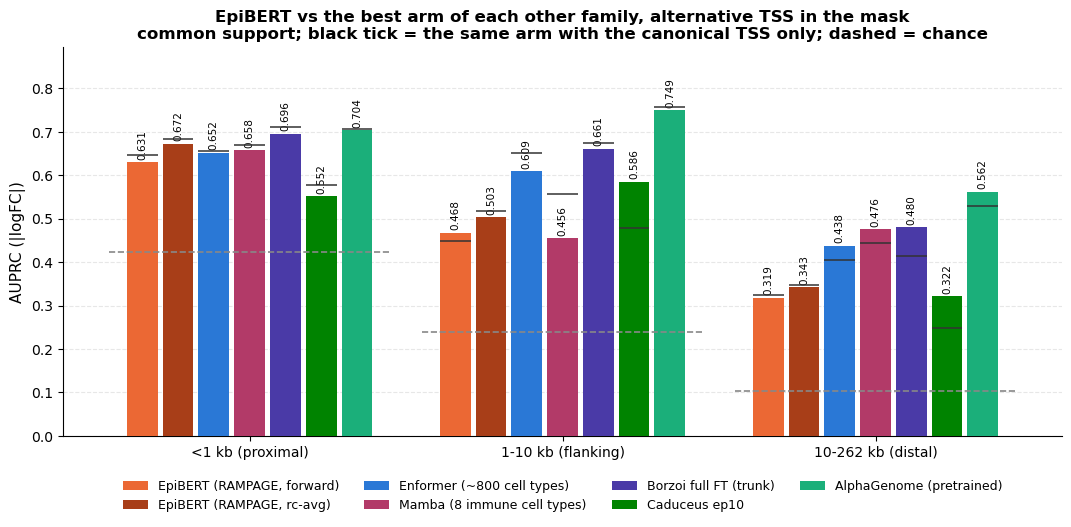

EpiBERT and the best of each other family, alt-TSS mask, common support, AUPRC:


,family,<1 kb (proximal),1-10 kb (flanking),10-262 kb (distal)
"EpiBERT (RAMPAGE, forward)",EpiBERT,0.6308,0.4682,0.3185
"EpiBERT (RAMPAGE, rc-avg)",EpiBERT,0.6725,0.5033,0.3431
Enformer (~800 cell types),Enformer,0.6519,0.6090,0.4380
Mamba (8 immune cell types),Mamba,0.6578,0.4555,0.4761
Borzoi full FT (trunk),Borzoi,0.6961,0.6614,0.4804
Caduceus ep10,Caduceus,0.5521,0.5856,0.3215
AlphaGenome (pretrained),AlphaGenome,0.7040,0.7494,0.5620



proximal - distal AUPRC with the alt-TSS mask (how fast each arm falls off), and how that slope changed:


,alt TSS,canonical,delta
"EpiBERT (RAMPAGE, rc-avg)",0.3294,0.3379,-0.0086
"EpiBERT (RAMPAGE, forward)",0.3122,0.3221,-0.0099
Borzoi LoRA v2,0.2647,0.2655,-0.0008
Caduceus ep4,0.2592,0.4040,-0.1448
Caduceus ep10,0.2306,0.3303,-0.0997
Borzoi full FT (trunk),0.2157,0.2963,-0.0806
Enformer (~800 cell types),0.2138,0.2512,-0.0373
Borzoi from scratch,0.2016,0.2577,-0.0561
Borzoi (pretrained),0.1857,0.2528,-0.0671
Mamba (8 immune cell types),0.1817,0.2264,-0.0447


In [15]:
# §15 - EpiBERT against the best of each other family, alt-TSS mask, common support.
best_alt = {}
for a in ARMS:
    if a.family == 'EpiBERT':
        continue
    i = KEYS.index(a.key)
    score = AUPRC_ALT_COMMON[:, i].mean()
    if a.family not in best_alt or score > best_alt[a.family][1]:
        best_alt[a.family] = (a, score)
panel_alt = [a for a in ARMS if a.family == 'EpiBERT'] + [v[0] for v in best_alt.values()]
idx_alt = [KEYS.index(a.key) for a in panel_alt]

fig, ax = plt.subplots(figsize=(11, 5.4))
x = np.arange(len(BIN_NAMES))
w = 0.8 / len(panel_alt)
for j, i in enumerate(idx_alt):
    off = (j - (len(panel_alt) - 1) / 2) * w
    ax.bar(x + off, AUPRC_ALT_COMMON[:, i], width=w * 0.86,
           color=ARMS[i].color, label=ARMS[i].label, zorder=3)
    #canonical value as a tick on the same bar, so the change is legible without a second panel
    ax.hlines(AUPRC_COMMON[:, i], x + off - w * 0.43, x + off + w * 0.43,
              color='#333333', lw=1.1, zorder=5)
    for bi in range(len(BIN_NAMES)):
        ax.text(x[bi] + off, AUPRC_ALT_COMMON[bi, i] + 0.006,
                f'{AUPRC_ALT_COMMON[bi, i]:.3f}',
                ha='center', va='bottom', fontsize=7.5, rotation=90)
for bi, m in enumerate([d & COMMON for d in DIST_MASKS]):
    ax.hlines(labels[m].mean(), x[bi] - 0.45, x[bi] + 0.45,
              ls='--', lw=1.2, color='#888888', zorder=4)
ax.set_xticks(x)
ax.set_xticklabels(BIN_NAMES, fontsize=10)
ax.set_ylabel('AUPRC (|logFC|)', fontsize=11)
ax.set_ylim(0, max(AUPRC_ALT_COMMON[:, idx_alt].max(), AUPRC_COMMON[:, idx_alt].max()) * 1.18)
ax.set_title('EpiBERT vs the best arm of each other family, alternative TSS in the mask\n'
             'common support; black tick = the same arm with the canonical TSS only; '
             'dashed = chance', fontsize=12, fontweight='bold')
ax.legend(fontsize=9, frameon=False, ncol=4, loc='upper center',
          bbox_to_anchor=(0.5, -0.1), borderaxespad=0)
ax.grid(axis='y', ls='--', alpha=0.3, zorder=0)
ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()

print('EpiBERT and the best of each other family, alt-TSS mask, common support, AUPRC:')
display(auprc_frame(AUPRC_ALT_COMMON).iloc[idx_alt])

drop_alt = AUPRC_ALT_COMMON[0, :] - AUPRC_ALT_COMMON[2, :]
print('\nproximal - distal AUPRC with the alt-TSS mask (how fast each arm falls off), '
      'and how that slope changed:')
display(pd.DataFrame({
    'alt TSS': drop_alt,
    'canonical': AUPRC_COMMON[0, :] - AUPRC_COMMON[2, :],
    'delta': drop_alt - (AUPRC_COMMON[0, :] - AUPRC_COMMON[2, :]),
}, index=[a.label for a in ARMS]).sort_values('alt TSS', ascending=False).round(4))

## 16. Is the result an artefact of one arbitrary window width?

`ALT_HALF_BP = 1024` was chosen only to match the main window. `SWEEP_HALF_BP` re-scores
every arm at 256, 512, 1024 and 2048 bp around each alternative promoter; the main window
stays at ±1024 bp throughout, so the sweep isolates the alternative-TSS contribution.
`x = 0` is the canonical mask, i.e. §3.

A flat sweep means the alternative TSS carry no signal at any width. A sweep that rises then
falls means the promoters help but the window is eventually diluting them with intergenic
bins. A monotone rise all the way to 2048 bp would mean the width is not yet saturated and
the panel above is a lower bound.

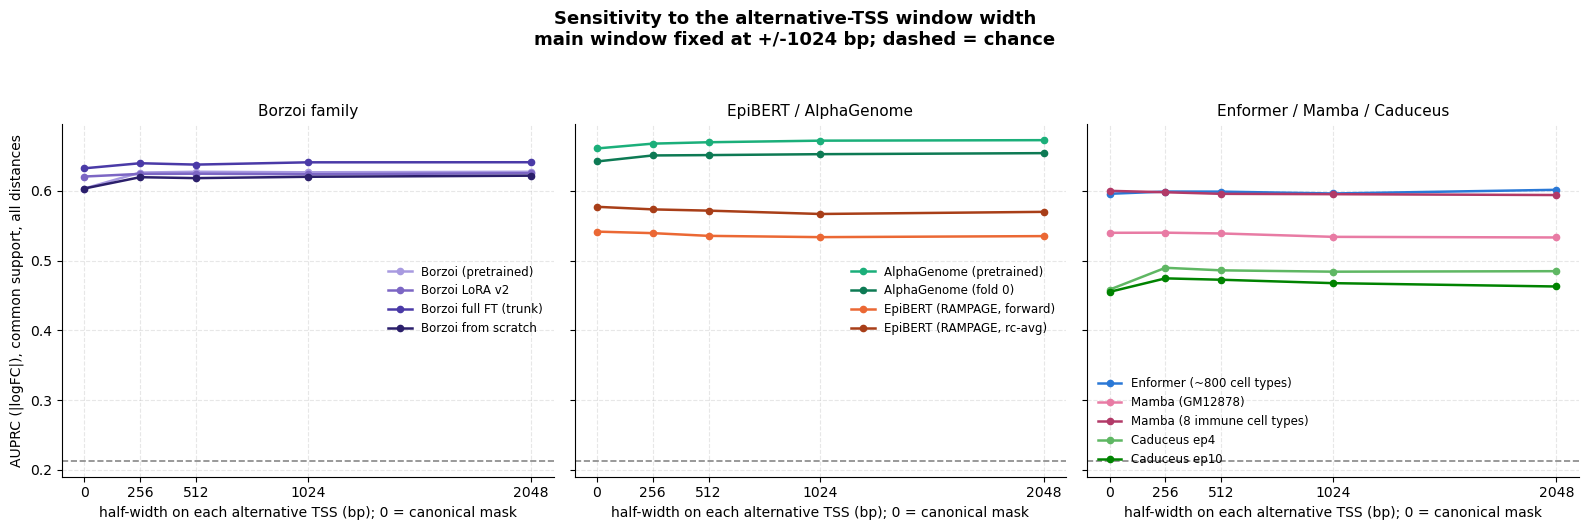

AUPRC on common support, pooled over distance, at each alternative-TSS window width:


,canonical,256 bp,512 bp,1024 bp,2048 bp,best width,best - canonical
Enformer (~800 cell types),0.5956,0.5989,0.5987,0.5961,0.6014,2048,0.0057
Mamba (GM12878),0.5397,0.5399,0.5388,0.5339,0.5330,256,0.0002
Mamba (8 immune cell types),0.5999,0.5979,0.5956,0.5951,0.5939,0,0.0000
Borzoi (pretrained),0.6031,0.6261,0.6272,0.6265,0.6272,512,0.0241
Borzoi LoRA v2,0.6204,0.6242,0.6244,0.6236,0.6252,2048,0.0048
Borzoi full FT (trunk),0.6322,0.6394,0.6375,0.6407,0.6409,2048,0.0087
Borzoi from scratch,0.6032,0.6194,0.6181,0.6200,0.6216,2048,0.0184
Caduceus ep4,0.4583,0.4896,0.4859,0.4840,0.4847,256,0.0313
Caduceus ep10,0.4550,0.4744,0.4724,0.4676,0.4628,256,0.0194
AlphaGenome (pretrained),0.6606,0.6675,0.6695,0.6718,0.6725,2048,0.0119


In [16]:
# §16 - AUPRC vs the alternative-TSS window width.
SWEEP_X = [0] + SWEEP_HALF_BP
sweep_auprc = {}
for a in ARMS:
    vals = []
    for h in SWEEP_X:
        s = SCORES[a.key]['logfc'] if h == 0 else SWEEP_LOGFC[a.key][h]
        pr, rc, _ = precision_recall_curve(labels[COMMON], s[COMMON])
        vals.append(auc(rc, pr))
    sweep_auprc[a.key] = np.array(vals)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.0), sharex=True, sharey=True)
for ax, (facet_name, fams) in zip(axes, FACETS):
    for a in [x for x in ARMS if x.family in fams]:
        ax.plot(SWEEP_X, sweep_auprc[a.key], marker='o', ms=4.5, lw=1.8,
                color=a.color, label=a.label, zorder=3)
    ax.axhline(labels[COMMON].mean(), ls='--', lw=1.2, color='#888888', zorder=2)
    ax.set_title(facet_name, fontsize=11)
    ax.set_xticks(SWEEP_X)
    ax.set_xlabel('half-width on each alternative TSS (bp); 0 = canonical mask', fontsize=10)
    ax.grid(ls='--', alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(fontsize=8.5, frameon=False, loc='best')
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel('AUPRC (|logFC|), common support, all distances', fontsize=10)
fig.suptitle('Sensitivity to the alternative-TSS window width\n'
             'main window fixed at +/-1024 bp; dashed = chance',
             fontsize=13, fontweight='bold', y=1.05)
fig.tight_layout()
plt.show()

sweep_df = pd.DataFrame({f'{h} bp' if h else 'canonical': [sweep_auprc[a.key][j]
                                                           for a in ARMS]
                         for j, h in enumerate(SWEEP_X)},
                        index=[a.label for a in ARMS]).round(4)
sweep_df['best width'] = [SWEEP_X[int(np.argmax(sweep_auprc[a.key]))] for a in ARMS]
sweep_df['best - canonical'] = [round(sweep_auprc[a.key].max() - sweep_auprc[a.key][0], 4)
                                for a in ARMS]
print('AUPRC on common support, pooled over distance, at each alternative-TSS window width:')
display(sweep_df)

## 17. Distance, redefined

Everything above keeps the §1 distance bins, `|variant − canonical TSS|`, so the panels stay
subtractable. But once the model is asked about *all* of a gene's promoters, the honest
distance for a variant is the distance to the nearest one — and that reassigns a lot of rows.

This is reported rather than adopted: it changes bin membership *and* the per-bin positive
rate, so AUPRC under these bins is not comparable to anything in §3–§16. It is also
arm-independent — it uses every annotated TSS, including ones the narrow arms cannot see —
which is the right definition for a property of the benchmark rather than of a model.

In [17]:
# §17 - min-distance-to-any-TSS as a secondary stratification.
min_dist = np.zeros(N_QTL, dtype=int)
for i in range(N_QTL):
    pos = qtls['qtl_loc'].iloc[i] - 1
    t0 = geneTSS_dic[ordered_genes[qtls['gene_idx'].iloc[i]]]
    min_dist[i] = min([abs(t0 - pos)] + [abs(t0 + int(o) - pos) for o in ALT_OFFSETS[i]])
assert (min_dist <= distances).all(), 'min distance cannot exceed the canonical distance'

MIN_MASKS = [
    min_dist < THRESHOLDS[0],
    (min_dist >= THRESHOLDS[0]) & (min_dist < THRESHOLDS[1]),
    (min_dist >= THRESHOLDS[1]) & (min_dist < THRESHOLDS[2]),
]
print(f'{int((min_dist < distances).sum())} / {N_QTL} variants are nearer an alternative TSS '
      f'than the canonical one (median shortening '
      f'{int(np.median((distances - min_dist)[min_dist < distances])):,} bp)')

mig = pd.DataFrame(
    [[int((dm & mm).sum()) for mm in MIN_MASKS] + [int((dm & ~np.logical_or.reduce(MIN_MASKS)).sum())]
     for dm in DIST_MASKS],
    index=[f'canonical: {b}' for b in BIN_NAMES],
    columns=[f'nearest: {b}' for b in BIN_NAMES] + ['nearest: beyond 262 kb'])
print('\nbin migration (rows), canonical distance -> nearest-TSS distance:')
display(mig)

print('\nper-bin size and chance level under each definition:')
display(pd.DataFrame({
    'n (canonical)': [int(m.sum()) for m in DIST_MASKS],
    'chance (canonical)': [round(labels[m].mean(), 4) for m in DIST_MASKS],
    'n (nearest)': [int(m.sum()) for m in MIN_MASKS],
    'chance (nearest)': [round(labels[m].mean(), 4) for m in MIN_MASKS],
}, index=BIN_NAMES))


def auprc_table_bins(score_dict, bin_masks, score_key='logfc', row_mask=None):
    out = np.zeros((len(bin_masks), len(ARMS)))
    for bi, dm in enumerate(bin_masks):
        m = dm if row_mask is None else (dm & row_mask)
        for ai, a in enumerate(ARMS):
            pr, rc, _ = precision_recall_curve(labels[m], score_dict[a.key][score_key][m])
            out[bi, ai] = auc(rc, pr)
    return out


AUPRC_ALT_MIN = auprc_table_bins(SCORES_ALT, MIN_MASKS, row_mask=COMMON)
print('\nAUPRC with the alt-TSS mask, binned on distance to the NEAREST TSS, common support.')
print('Not comparable to §13 -- the bins hold different rows and have different chance levels:')
display(auprc_frame(AUPRC_ALT_MIN))

533 / 1331 variants are nearer an alternative TSS than the canonical one (median shortening 18,117 bp)

bin migration (rows), canonical distance -> nearest-TSS distance:


,nearest: <1 kb (proximal),nearest: 1-10 kb (flanking),nearest: 10-262 kb (distal),nearest: beyond 262 kb
canonical: <1 kb (proximal),291,0,0,0
canonical: 1-10 kb (flanking),50,96,0,0
canonical: 10-262 kb (distal),44,113,673,0



per-bin size and chance level under each definition:


,n (canonical),chance (canonical),n (nearest),chance (nearest)
<1 kb (proximal),291,0.4227,385,0.3974
1-10 kb (flanking),146,0.2397,210,0.1810
10-262 kb (distal),830,0.0843,682,0.0557



AUPRC with the alt-TSS mask, binned on distance to the NEAREST TSS, common support.
Not comparable to §13 -- the bins hold different rows and have different chance levels:


,family,<1 kb (proximal),1-10 kb (flanking),10-262 kb (distal)
Enformer (~800 cell types),Enformer,0.6372,0.5402,0.4101
Mamba (GM12878),Mamba,0.5854,0.4207,0.3302
Mamba (8 immune cell types),Mamba,0.6477,0.4266,0.4548
Borzoi (pretrained),Borzoi,0.6767,0.5424,0.4298
Borzoi LoRA v2,Borzoi,0.6751,0.5650,0.4191
Borzoi full FT (trunk),Borzoi,0.6915,0.5778,0.3602
Borzoi from scratch,Borzoi,0.6679,0.5407,0.3741
Caduceus ep4,Caduceus,0.5877,0.3854,0.1200
Caduceus ep10,Caduceus,0.5698,0.4198,0.1923
AlphaGenome (pretrained),AlphaGenome,0.7131,0.7018,0.4440


## 18. What Part 2 changed

The three numbers that decide whether alternative-TSS handling matters on this benchmark:
how many rows the mask actually moved, how much AUPRC moved on exactly those rows, and
whether the sweep says the effect survives a change of window width.

In [18]:
# §18 - the summary.
summary = []
for a in ARMS:
    m = ROWS_MOVED[a.key]
    i = KEYS.index(a.key)
    row = {'arm': a.label, 'family': a.family,
           'rows moved': int(m.sum()),
           'alt TSS dropped (out of reach)': DROPPED[a.key]}
    for bi, nm in enumerate(BIN_NAMES):
        row['d ' + nm.split(' ')[0]] = round(AUPRC_ALT_COMMON[bi, i] - AUPRC_COMMON[bi, i], 4)
    row['d pooled'] = round(sweep_auprc[a.key][SWEEP_X.index(ALT_HALF_BP)]
                            - sweep_auprc[a.key][0], 4)
    row['best width'] = SWEEP_X[int(np.argmax(sweep_auprc[a.key]))]
    summary.append(row)
summary = pd.DataFrame(summary).set_index('arm')
print('Part 2 summary. "d" columns are alt-TSS minus canonical on common support; '
      '"d pooled" is over all distances.')
display(summary)

print(f'\narms improved by the alternative-TSS mask (pooled, common support): '
      f'{int((summary["d pooled"] > 0).sum())} / {len(ARMS)}')
print(f'median pooled delta: {summary["d pooled"].median():+.4f}   '
      f'range [{summary["d pooled"].min():+.4f}, {summary["d pooled"].max():+.4f}]')
print(f'arms whose best sweep width is the canonical mask (0 bp): '
      f'{int((summary["best width"] == 0).sum())} / {len(ARMS)}')

Part 2 summary. "d" columns are alt-TSS minus canonical on common support; "d pooled" is over all distances.


,family,rows moved,alt TSS dropped (out of reach),d <1,d 1-10,d 10-262,d pooled,best width
arm,,,,,,,,
Enformer (~800 cell types),Enformer,771,1101,-0.0041,-0.0415,0.0332,0.0005,2048
Mamba (GM12878),Mamba,947,1780,-0.0096,-0.0564,0.0352,-0.0058,256
Mamba (8 immune cell types),Mamba,947,1780,-0.0121,-0.1004,0.0326,-0.0048,0
Borzoi (pretrained),Borzoi,963,1015,0.0006,0.0192,0.0678,0.0233,512
Borzoi LoRA v2,Borzoi,963,1015,-0.0029,-0.0002,-0.0021,0.0033,2048
Borzoi full FT (trunk),Borzoi,963,1015,-0.0148,-0.0123,0.0658,0.0086,2048
Borzoi from scratch,Borzoi,963,1015,-0.0071,0.0269,0.0490,0.0168,2048
Caduceus ep4,Caduceus,963,1015,-0.0109,0.0821,0.1339,0.0258,256
Caduceus ep10,Caduceus,963,1015,-0.0259,0.1062,0.0738,0.0125,256



arms improved by the alternative-TSS mask (pooled, common support): 9 / 13
median pooled delta: +0.0086   range [-0.0103, +0.0258]
arms whose best sweep width is the canonical mask (0 bp): 3 / 13
